# Name: Muhammad Haziq Faiz Bin Mohd Ripin
# ID: 24218182
# xAI Assignment 3

## Task 1:  (5 marks) 
* Import  Libraries 

* Load  the images 

* Separate  the Input  and Target  Features  of the  images 

* Split the  data  into  Train and  Test  Sets 

* Scale your data  if required 

In [62]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, WeightedRandomSampler
# Metrics
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path
import cv2
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
import shutil
from pathlib import Path

from collections import Counter
import time
import copy
# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (15, 10)

In [63]:
# Device configuration
if torch.cuda.is_available():
    device = torch.device('cuda')
    print(f"Using device: CUDA - {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    print(f"Using device: MPS (Apple Silicon)")
else:
    device = torch.device('cpu')
    print(f"Using device: CPU")

# Dataset paths
DATA_DIR = Path('chest_xray')
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'

Using device: MPS (Apple Silicon)


In [64]:
# Data transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                        std=[0.229, 0.224, 0.225])
])

# Load datasets
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(root=VAL_DIR, transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_test_transform)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Classes: {train_dataset.classes}")

Training samples: 5216
Validation samples: 16
Test samples: 624
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
def redistribute_dataset(original_train_dir, original_val_dir, original_test_dir, 
                         output_dir, split_ratio=(0.7, 0.15, 0.15)):
    """
    Redistribute data into more balanced train/val/test splits.
    """
    # Combine all data first
    all_data = []
    
    for class_dir in Path(original_train_dir).iterdir():
        if class_dir.is_dir():
            class_name = class_dir.name
            for img in class_dir.glob('*.*'):
                all_data.append((img, class_name))
    
    for class_dir in Path(original_val_dir).iterdir():
        if class_dir.is_dir():
            class_name = class_dir.name
            for img in class_dir.glob('*.*'):
                all_data.append((img, class_name))
    
    for class_dir in Path(original_test_dir).iterdir():
        if class_dir.is_dir():
            class_name = class_dir.name
            for img in class_dir.glob('*.*'):
                all_data.append((img, class_name))
    
    # Separate by class for stratified split
    from collections import defaultdict
    class_data = defaultdict(list)
    for img_path, class_name in all_data:
        class_data[class_name].append(img_path)
    
    # Create new directories
    output_path = Path(output_dir)
    for split in ['train', 'val', 'test']:
        for class_name in class_data.keys():
            (output_path / split / class_name).mkdir(parents=True, exist_ok=True)
    
    # Split each class
    for class_name, images in class_data.items():
        # Shuffle
        import random
        random.shuffle(images)
        
        # Calculate split points
        n = len(images)
        train_end = int(n * split_ratio[0])
        val_end = train_end + int(n * split_ratio[1])
        
        train_imgs = images[:train_end]
        val_imgs = images[train_end:val_end]
        test_imgs = images[val_end:]
        
        # Copy files
        for img in train_imgs:
            shutil.copy2(img, output_path / 'train' / class_name / img.name)
        for img in val_imgs:
            shutil.copy2(img, output_path / 'val' / class_name / img.name)
        for img in test_imgs:
            shutil.copy2(img, output_path / 'test' / class_name / img.name)
        
        print(f"{class_name}: Train={len(train_imgs)}, Val={len(val_imgs)}, Test={len(test_imgs)}")
    
    print(f"\n✓ Data redistributed to {output_dir}")
    print(f"  New split: {split_ratio[0]*100:.0f}% / {split_ratio[1]*100:.0f}% / {split_ratio[2]*100:.0f}%")

# Use it
redistribute_dataset(
    original_train_dir='chest_xray/train',
    original_val_dir='chest_xray/val',
    original_test_dir='chest_xray/test',
    output_dir='chest_xray_balanced',
    split_ratio=(0.7, 0.15, 0.15)  # 70% train, 15% val, 15% test
)

PNEUMONIA: Train=2991, Val=640, Test=642
NORMAL: Train=1108, Val=237, Test=238

✓ Data redistributed to chest_xray_balanced
  New split: 70% / 15% / 15%


In [66]:
# Balanced dataset paths
DATA_DIR = Path('chest_xray_balanced')
TRAIN_DIR = DATA_DIR / 'train'
VAL_DIR = DATA_DIR / 'val'
TEST_DIR = DATA_DIR / 'test'

# Load balanced datasets
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(root=VAL_DIR, transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_test_transform)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Classes: {train_dataset.classes}")

Training samples: 5683
Validation samples: 2270
Test samples: 2251
Classes: ['NORMAL', 'PNEUMONIA']


In [112]:
# check the statistics of the dataset to detect any imbalance
def count_files(directory):
    """Count files in each class subdirectory."""
    counts = {}
    if not directory.exists():
        return counts
    
    for class_dir in directory.iterdir():
        if class_dir.is_dir():
            counts[class_dir.name] = len(list(class_dir.glob('*.*')))
    return counts

# Count files in each split
train_counts = count_files(TRAIN_DIR)
val_counts = count_files(VAL_DIR)
test_counts = count_files(TEST_DIR)

print(f"\nTraining set:")
for class_name, count in train_counts.items():
    print(f"  {class_name}: {count} images")
print(f"  Total: {sum(train_counts.values())} images")

print(f"\nValidation set:")
for class_name, count in val_counts.items():
    print(f"  {class_name}: {count} images")
print(f"  Total: {sum(val_counts.values())} images")

print(f"\nTest set:")
for class_name, count in test_counts.items():
    print(f"  {class_name}: {count} images")
print(f"  Total: {sum(test_counts.values())} images")


Training set:
  PNEUMONIA: 4155 images
  NORMAL: 1528 images
  Total: 5683 images

Validation set:
  PNEUMONIA: 1653 images
  NORMAL: 617 images
  Total: 2270 images

Test set:
  PNEUMONIA: 1653 images
  NORMAL: 598 images
  Total: 2251 images


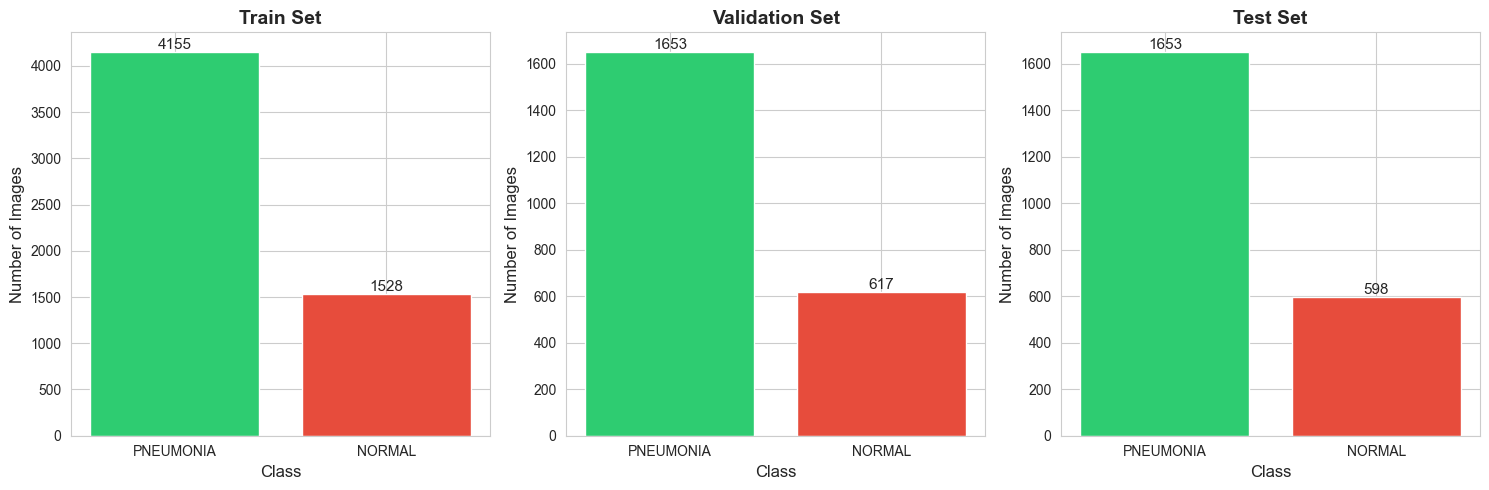


Class Distribution in Training Set:
  PNEUMONIA: 73.11%
  NORMAL: 26.89%


In [68]:
# Create a bar chart showing class distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

splits = [('Train', train_counts), ('Validation', val_counts), ('Test', test_counts)]

for ax, (split_name, counts) in zip(axes, splits):
    if counts:
        classes = list(counts.keys())
        values = list(counts.values())
        colors = ['#2ecc71', '#e74c3c']
        
        bars = ax.bar(classes, values, color=colors[:len(classes)])
        ax.set_title(f'{split_name} Set', fontsize=14, fontweight='bold')
        ax.set_ylabel('Number of Images', fontsize=12)
        ax.set_xlabel('Class', fontsize=12)
        
        # Add value labels on bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{int(height)}',
                   ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

# Calculate and display class imbalance
if train_counts:
    total = sum(train_counts.values())
    print("\nClass Distribution in Training Set:")
    for class_name, count in train_counts.items():
        percentage = (count / total) * 100
        print(f"  {class_name}: {percentage:.2f}%")

In [69]:
# Load Dataset
train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(root=VAL_DIR, transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=val_test_transform)

print("Datasets loaded successfully!")
print(f"\nTraining samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

# Display class to index mapping
print(f"\nClass to index mapping: {train_dataset.class_to_idx}")
print(f"Classes: {train_dataset.classes}")

Datasets loaded successfully!

Training samples: 5683
Validation samples: 2270
Test samples: 2251

Class to index mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Classes: ['NORMAL', 'PNEUMONIA']


In [113]:
# Create a weighted sampler that oversamples minority class
def create_weighted_sampler(dataset):
    """Create a WeightedRandomSampler for balanced sampling."""
    # Get all labels
    labels = [label for _, label in dataset]
    class_counts = Counter(labels)
    
    # Calculate weight for each sample (inverse of class frequency)
    class_weights = {class_idx: 1.0 / count for class_idx, count in class_counts.items()}
    sample_weights = [class_weights[label] for label in labels]
    
    # Create sampler
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )
    
    return sampler

weighted_sampler = create_weighted_sampler(train_dataset)
print("Weighted sampler created")

Weighted sampler created


In [71]:
# Hyperparameters
BATCH_SIZE = 32
NUM_WORKERS = 16  # Adjust based on your CPU cores

print("Creating data loaders WITH weighted sampling...")
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=weighted_sampler,  # Use sampler instead of shuffle
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)
    
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nNumber of batches:")
print(f"  Training: {len(train_loader)}")
print(f"  Validation: {len(val_loader)}")
print(f"  Test: {len(test_loader)}")

Creating data loaders WITH weighted sampling...

Number of batches:
  Training: 178
  Validation: 71
  Test: 71


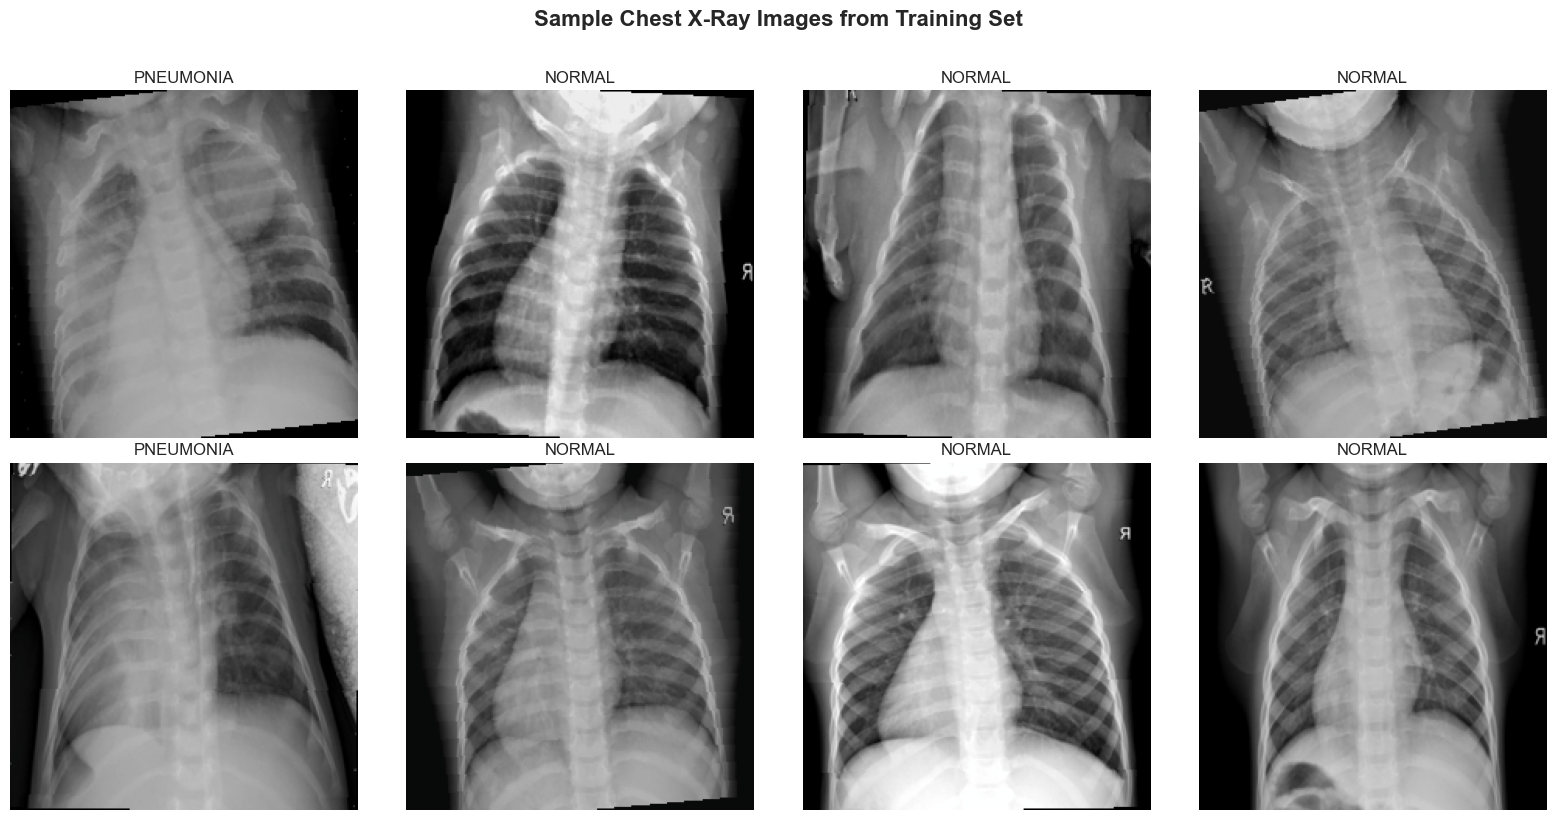

In [72]:
def imshow(img, title=None):
    """Display a tensor image."""
    img = img.numpy().transpose((1, 2, 0))
    # Denormalize
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
    if title:
        plt.title(title, fontsize=12)
    plt.axis('off')

# Get a batch of training data
images, labels = next(iter(train_loader))

# Display 8 sample images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for idx in range(8):
    plt.subplot(2, 4, idx + 1)
    imshow(images[idx].cpu(), 
           title=f"{train_dataset.classes[labels[idx]]}")

plt.suptitle('Sample Chest X-Ray Images from Training Set', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Task 2:  (5 marks) 
* Train and  compare  three  Machine  Learning/Deep  Learning  Models   

* Evaluate  the  model  using  F1 Score 

Model 1: Custom CNN

In [114]:
class CustomCNN(nn.Module):
    """Custom CNN
    """
    def __init__(self, num_classes=2):
        super(CustomCNN, self).__init__()
        
        # Convolutional Block 1
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Convolutional Block 2
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Convolutional Block 3
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Convolutional Block 4
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        # Global Average Pooling
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        
        # Fully Connected Layers
        self.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
        
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.global_avg_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

# Create model
model_cnn = CustomCNN(num_classes=2).to(device)

# Count parameters
total_params = sum(p.numel() for p in model_cnn.parameters())
trainable_params = sum(p.numel() for p in model_cnn.parameters() if p.requires_grad)

print(f"Custom CNN created")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Custom CNN created
Total parameters: 1,207,330
Trainable parameters: 1,207,330


Model 2: Pre-Trained ResNet18 With Transfer Learning

In [115]:
# Load pre-trained ResNet18
model_resnet = models.resnet18(pretrained=True)

# Freeze early layers (optional - comment out to fine-tune all layers)
for param in model_resnet.parameters():
    param.requires_grad = False

# Unfreeze last residual block and FC layer for fine-tuning
for param in model_resnet.layer4.parameters():
    param.requires_grad = True

# Replace final fully connected layer
num_features = model_resnet.fc.in_features
model_resnet.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 128),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(128, 2)
)

model_resnet = model_resnet.to(device)

# Count parameters
total_params = sum(p.numel() for p in model_resnet.parameters())
trainable_params = sum(p.numel() for p in model_resnet.parameters() if p.requires_grad)

print(f"ResNet18 created with transfer learning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet18 created with transfer learning
Total parameters: 11,242,434
Trainable parameters: 8,459,650
Frozen parameters: 2,782,784


Model 3: EfficientNet-B0

In [116]:
# Load pre-trained EfficientNet-B0
model_efficient = models.efficientnet_b0(pretrained=True)

# Freeze early layers
for param in model_efficient.features[:-3].parameters():
    param.requires_grad = False

# Replace classifier
num_features = model_efficient.classifier[1].in_features
model_efficient.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(256, 2)
)

model_efficient = model_efficient.to(device)

# Count parameters
total_params = sum(p.numel() for p in model_efficient.parameters())
trainable_params = sum(p.numel() for p in model_efficient.parameters() if p.requires_grad)

print(f"EfficientNet-B0 created with transfer learning")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


EfficientNet-B0 created with transfer learning
Total parameters: 4,335,998
Trainable parameters: 3,484,190
Frozen parameters: 851,808


In [117]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    """Train model for one epoch."""
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    pbar = tqdm(train_loader, desc='Training')
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        
        # Forward pass
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average='weighted')
    
    return epoch_loss, epoch_f1


def validate(model, val_loader, criterion, device):
    """Validate model."""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc='Validation'):
            images, labels = images.to(device), labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_f1 = f1_score(all_labels, all_preds, average='weighted')
    
    return epoch_loss, epoch_f1


def train_model(model, model_name, train_loader, val_loader, criterion, optimizer, 
                scheduler=None, num_epochs=10, device='cuda'):
    """Complete training loop with validation."""
    print(f"\n{'='*60}")
    print(f"Training {model_name}")
    print(f"{'='*60}\n")
    
    history = {
        'train_loss': [],
        'train_f1': [],
        'val_loss': [],
        'val_f1': []
    }
    
    best_f1 = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    
    start_time = time.time()
    
    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print('-' * 40)
        
        # Train
        train_loss, train_f1 = train_one_epoch(model, train_loader, criterion, optimizer, device)
        
        # Validate
        val_loss, val_f1 = validate(model, val_loader, criterion, device)
        
        # Update learning rate
        if scheduler is not None:
            scheduler.step()
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_f1'].append(train_f1)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        
        print(f"\nTrain Loss: {train_loss:.4f} | Train F1: {train_f1:.4f}")
        print(f"Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f}")
        
        # Save best model
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            print(f"✓ New best F1 score: {best_f1:.4f}")
    
    training_time = time.time() - start_time
    
    print(f"\n{'='*60}")
    print(f"Training complete in {training_time//60:.0f}m {training_time%60:.0f}s")
    print(f"Best Validation F1: {best_f1:.4f}")
    print(f"{'='*60}\n")
    
    # Load best model weights
    model.load_state_dict(best_model_wts)
    
    return model, history, best_f1

print("Training functions defined")

Training functions defined


In [118]:
def evaluate_model(model, test_loader, device, class_names):
    """Comprehensive evaluation on test set."""
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc='Testing'):
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    # Calculate F1 scores
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_per_class = f1_score(all_labels, all_preds, average=None)
    
    # Print results
    print("\n" + "="*60)
    print("TEST SET EVALUATION")
    print("="*60)
    print(f"\nWeighted F1 Score: {f1_weighted:.4f}")
    print(f"Macro F1 Score: {f1_macro:.4f}")
    print("\nPer-class F1 Scores:")
    for i, class_name in enumerate(class_names):
        print(f"  {class_name}: {f1_per_class[i]:.4f}")
    
    # Detailed classification report
    print("\n" + "="*60)
    print("DETAILED CLASSIFICATION REPORT")
    print("="*60)
    print(classification_report(all_labels, all_preds, target_names=class_names))
    
    # Confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    
    return {
        'f1_weighted': f1_weighted,
        'f1_macro': f1_macro,
        'f1_per_class': f1_per_class,
        'predictions': all_preds,
        'labels': all_labels,
        'confusion_matrix': cm
    }

print("Evaluation function defined")

Evaluation function defined


In [119]:
def plot_training_history(history, model_name):
    """Plot training and validation metrics."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    # Loss
    axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
    axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title(f'{model_name} - Loss', fontsize=14, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # F1 Score
    axes[1].plot(history['train_f1'], label='Train F1', marker='o')
    axes[1].plot(history['val_f1'], label='Val F1', marker='s')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title(f'{model_name} - F1 Score', fontsize=14, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, class_names, model_name):
    """Plot confusion matrix."""
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'})
    plt.title(f'{model_name} - Confusion Matrix', fontsize=14, fontweight='bold')
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.tight_layout()
    plt.show()

print("Visualization functions defined")

Visualization functions defined


In [79]:
# Training hyperparameters
NUM_EPOCHS = 7
LEARNING_RATE = 0.001

# Loss function with class weights
criterion = nn.CrossEntropyLoss(weight=class_weights)

print(f"Training Configuration:")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Learning Rate: {LEARNING_RATE}")
print(f"  Loss Function: Weighted CrossEntropyLoss")
print(f"  Class Weights: {class_weights}")

Training Configuration:
  Epochs: 7
  Learning Rate: 0.001
  Loss Function: Weighted CrossEntropyLoss
  Class Weights: tensor([1.9448, 0.6730], device='mps:0')



Training Model 1: Custom CNN


Epoch 1/7
----------------------------------------


Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation: 100%|██████████| 71/71 [01:34<00:00,  1.33s/it]



Train Loss: 0.3179 | Train F1: 0.8107
Val Loss: 0.2774 | Val F1: 0.8836
✓ New best F1 score: 0.8836

Epoch 2/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.2436 | Train F1: 0.8627
Val Loss: 0.4636 | Val F1: 0.8101

Epoch 3/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha

... (5 outputs left out)

Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.1468 | Train F1: 0.9235
Val Loss: 0.2491 | Val F1: 0.9107
✓ New best F1 score: 0.9107

Epoch 7/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.1334 | Train F1: 0.9331
Val Loss: 0.2473 | Val F1: 0.9133
✓ New best F1 score: 0.9133

Training complete in 166m 50s
Best Validation F1: 0.9133



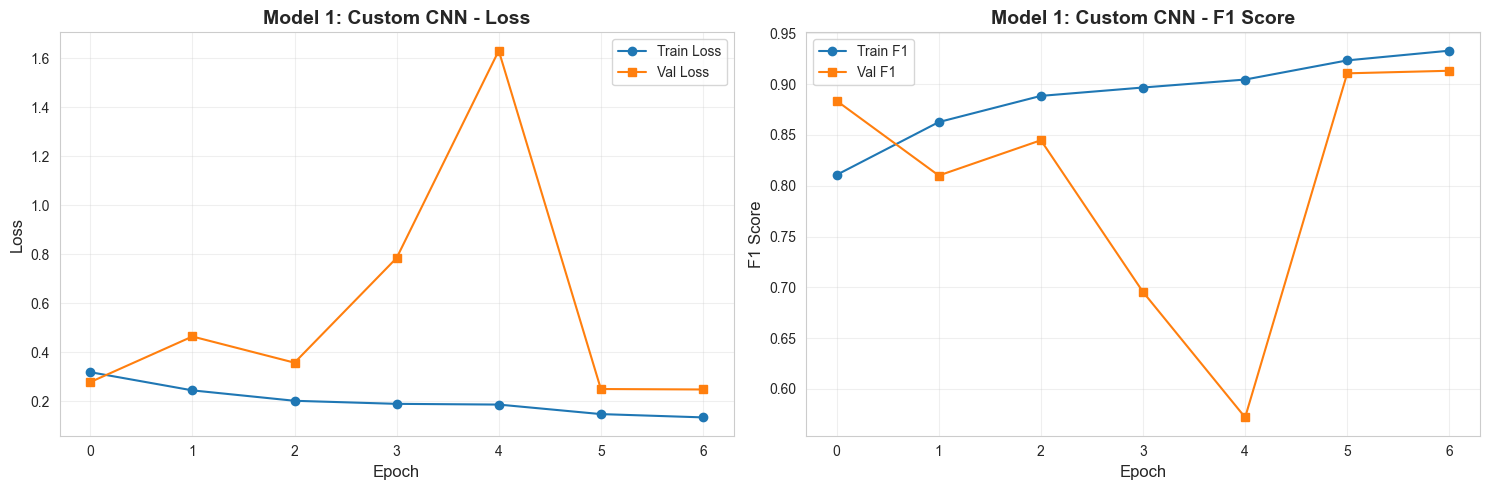

In [80]:
# Reset model
model_cnn = CustomCNN(num_classes=2).to(device)

# Optimizer and scheduler
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=LEARNING_RATE)
scheduler_cnn = optim.lr_scheduler.StepLR(optimizer_cnn, step_size=5, gamma=0.1)

# Train
model_cnn, history_cnn, best_f1_cnn = train_model(
    model_cnn, 
    "Model 1: Custom CNN",
    train_loader, 
    val_loader, 
    criterion, 
    optimizer_cnn,
    scheduler_cnn,
    num_epochs=NUM_EPOCHS,
    device=device
)

# Plot training history
plot_training_history(history_cnn, "Model 1: Custom CNN")

Testing:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Testing: 100%|██████████| 71/71 [01:33<00:00,  1.32s/it]



TEST SET EVALUATION

Weighted F1 Score: 0.9182
Macro F1 Score: 0.8998

Per-class F1 Scores:
  NORMAL: 0.8605
  PNEUMONIA: 0.9390

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.76      0.98      0.86       598
   PNEUMONIA       0.99      0.89      0.94      1653

    accuracy                           0.92      2251
   macro avg       0.88      0.94      0.90      2251
weighted avg       0.93      0.92      0.92      2251



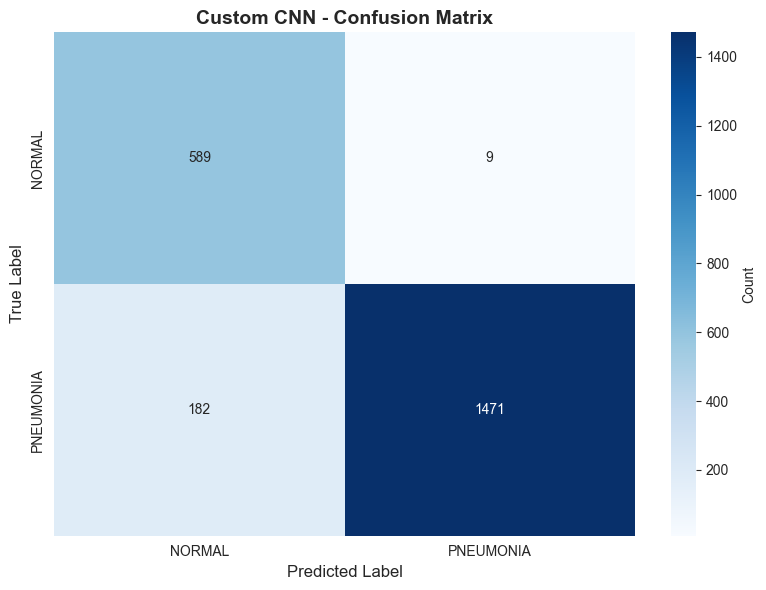

In [81]:
results_cnn = evaluate_model(model_cnn, test_loader, device, train_dataset.classes)
plot_confusion_matrix(results_cnn['confusion_matrix'], train_dataset.classes, "Custom CNN")
torch.save(model_cnn.state_dict(), 'custom_cnn_pneumonia_full.pth')

Train Model 2

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Training Model 2: ResNet18


Epoch 1/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.1382 | Train F1: 0.9320
Val Loss: 0.2887 | Val F1: 0.9056
✓ New best F1 score: 0.9056

Epoch 2/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.0949 | Train F1: 0.9560
Val Loss: 0.1343 | Val F1: 0.9530
✓ New best F1 score: 0.9530

Epoch 3/7
----------------------------------------


... (6 outputs left out)

Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.0563 | Train F1: 0.9762
Val Loss: 0.0832 | Val F1: 0.9662

Epoch 7/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.0471 | Train F1: 0.9745
Val Loss: 0.0572 | Val F1: 0.9756

Training complete in 26m 12s
Best Validation F1: 0.9793



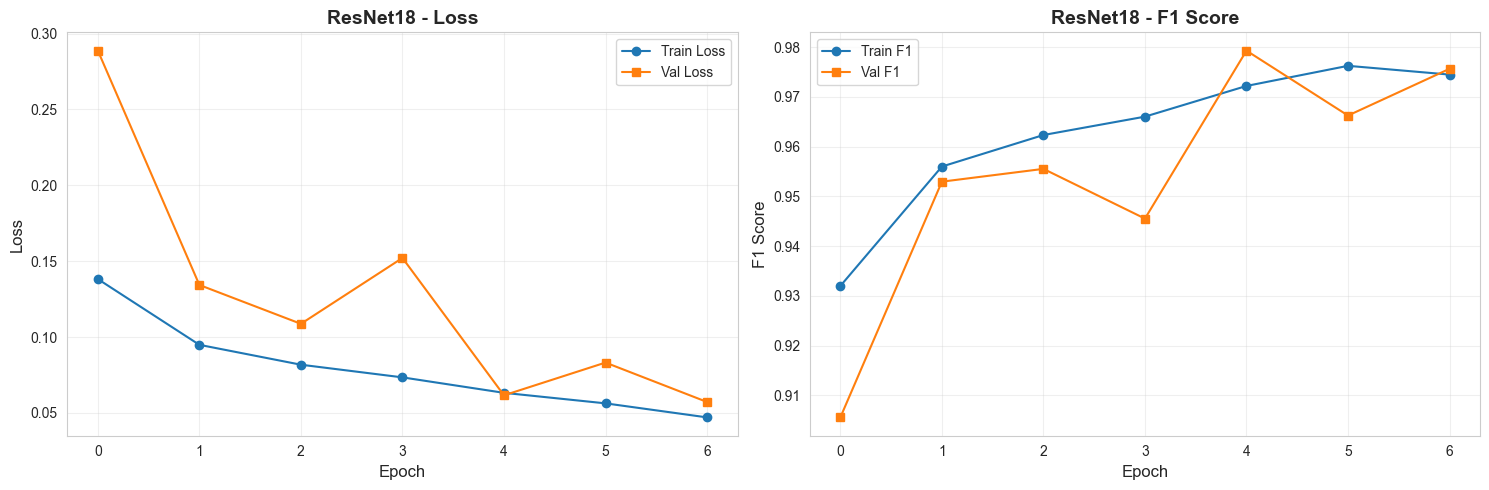

In [82]:
# Reset model
model_resnet = models.resnet18(pretrained=True)

# Freeze early layers
for param in model_resnet.parameters():
    param.requires_grad = False

for param in model_resnet.layer4.parameters():
    param.requires_grad = True

num_features = model_resnet.fc.in_features
model_resnet.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 128),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(128, 2)
)
model_resnet = model_resnet.to(device)

# Optimizer and scheduler
optimizer_resnet = optim.Adam(model_resnet.parameters(), lr=LEARNING_RATE)
scheduler_resnet = optim.lr_scheduler.StepLR(optimizer_resnet, step_size=5, gamma=0.1)

# Train
model_resnet, history_resnet, best_f1_resnet = train_model(
    model_resnet, 
    "Model 2: ResNet18",
    train_loader, 
    val_loader, 
    criterion, 
    optimizer_resnet,
    scheduler_resnet,
    num_epochs=NUM_EPOCHS,
    device=device
)

# Plot training history
plot_training_history(history_resnet, "ResNet18")

Testing:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Testing: 100%|██████████| 71/71 [17:54<00:00, 15.13s/it]



TEST SET EVALUATION

Weighted F1 Score: 0.9840
Macro F1 Score: 0.9795

Per-class F1 Scores:
  NORMAL: 0.9699
  PNEUMONIA: 0.9891

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.97      0.97      0.97       598
   PNEUMONIA       0.99      0.99      0.99      1653

    accuracy                           0.98      2251
   macro avg       0.98      0.98      0.98      2251
weighted avg       0.98      0.98      0.98      2251



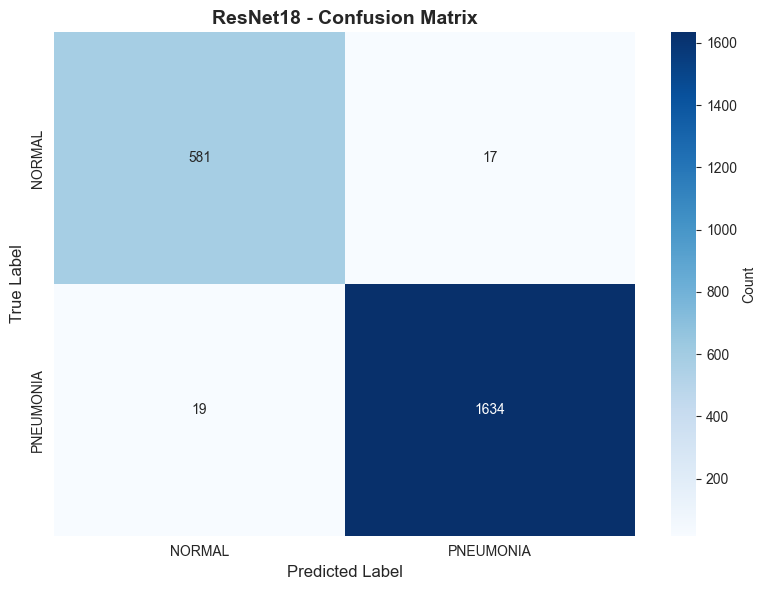

In [83]:
results_resnet = evaluate_model(model_resnet, test_loader, device, train_dataset.classes)
torch.save(model_resnet.state_dict(), 'resnet18_pneumonia_full.pth')
plot_confusion_matrix(results_resnet['confusion_matrix'], train_dataset.classes, "ResNet18")

Train Model 3

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Training Model 3: EfficientNet-B0


Epoch 1/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.1651 | Train F1: 0.9242
Val Loss: 0.4214 | Val F1: 0.8700
✓ New best F1 score: 0.8700

Epoch 2/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.1021 | Train F1: 0.9498
Val Loss: 0.0612 | Val F1: 0.9780
✓ New best F1 score: 0.9780

Epoch 3/7
----------------------------------------


... (6 outputs left out)

Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.0529 | Train F1: 0.9752
Val Loss: 0.0867 | Val F1: 0.9684

Epoch 7/7
----------------------------------------


Training:   0%|          | 0/178 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than wha


Train Loss: 0.0402 | Train F1: 0.9792
Val Loss: 0.0835 | Val F1: 0.9684

Training complete in 31m 4s
Best Validation F1: 0.9780



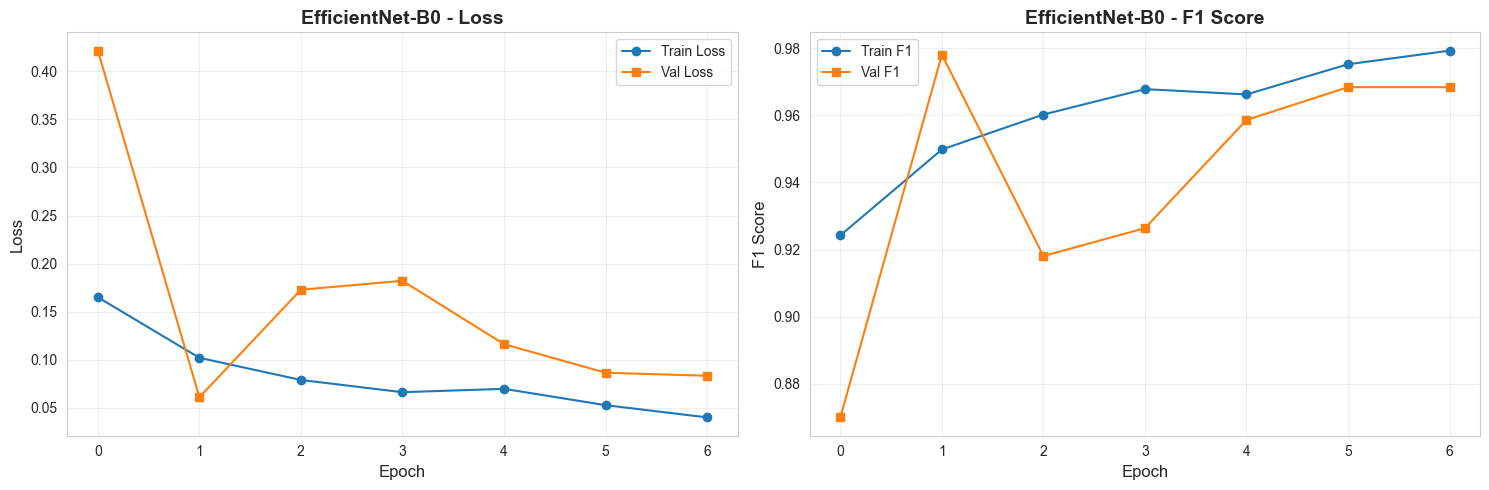

In [84]:
# Reset model
model_efficient = models.efficientnet_b0(pretrained=True)

# Freeze early layers
for param in model_efficient.features[:-3].parameters():
    param.requires_grad = False

num_features = model_efficient.classifier[1].in_features
model_efficient.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(256, 2)
)
model_efficient = model_efficient.to(device)

# Optimizer and scheduler
optimizer_efficient = optim.Adam(model_efficient.parameters(), lr=LEARNING_RATE)
scheduler_efficient = optim.lr_scheduler.StepLR(optimizer_efficient, step_size=5, gamma=0.1)

# Train
model_efficient, history_efficient, best_f1_efficient = train_model(
    model_efficient, 
    "Model 3: EfficientNet-B0",
    train_loader, 
    val_loader, 
    criterion, 
    optimizer_efficient,
    scheduler_efficient,
    num_epochs=NUM_EPOCHS,
    device=device
)

# Plot training history
plot_training_history(history_efficient, "EfficientNet-B0")

Testing:   0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Testing: 100%|██████████| 71/71 [01:34<00:00,  1.33s/it]



TEST SET EVALUATION

Weighted F1 Score: 0.9796
Macro F1 Score: 0.9739

Per-class F1 Scores:
  NORMAL: 0.9617
  PNEUMONIA: 0.9861

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.96      0.96      0.96       598
   PNEUMONIA       0.99      0.98      0.99      1653

    accuracy                           0.98      2251
   macro avg       0.97      0.97      0.97      2251
weighted avg       0.98      0.98      0.98      2251



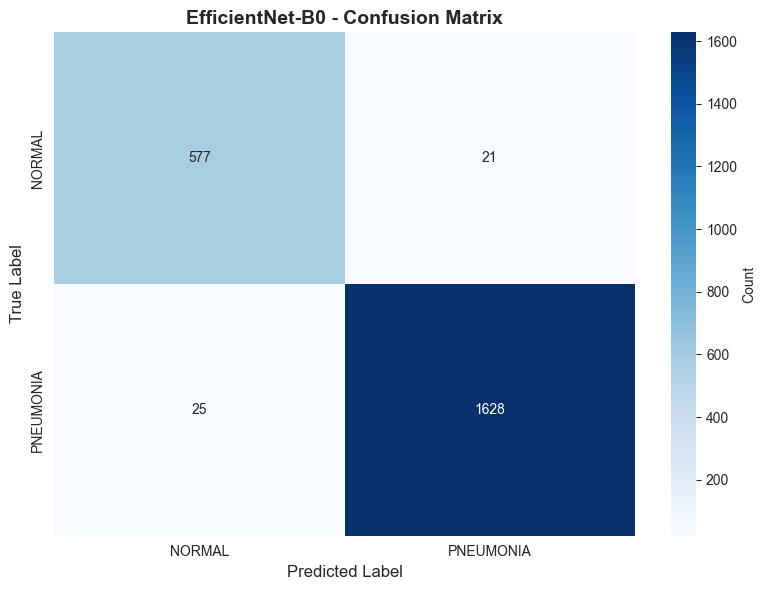

In [85]:
results_efficient = evaluate_model(model_efficient, test_loader, device, train_dataset.classes)
plot_confusion_matrix(results_efficient['confusion_matrix'], train_dataset.classes, "EfficientNet-B0")
torch.save(model_efficient.state_dict(), 'efficientnet_b0_pneumonia_full.pth')

In [120]:
# Compile results
comparison_data = {
    'Model': ['Custom CNN', 'ResNet18', 'EfficientNet-B0'],
    'Weighted F1': [
        results_cnn['f1_weighted'],
        results_resnet['f1_weighted'],
        results_efficient['f1_weighted']
    ],
    'Macro F1': [
        results_cnn['f1_macro'],
        results_resnet['f1_macro'],
        results_efficient['f1_macro']
    ],
    'NORMAL F1': [
        results_cnn['f1_per_class'][0],
        results_resnet['f1_per_class'][0],
        results_efficient['f1_per_class'][0]
    ],
    'PNEUMONIA F1': [
        results_cnn['f1_per_class'][1],
        results_resnet['f1_per_class'][1],
        results_efficient['f1_per_class'][1]
    ]
}

import pandas as pd
comparison_df = pd.DataFrame(comparison_data)


print("FINAL MODEL COMPARISON (F1 SCORES)")
print(comparison_df.to_string(index=False))

# Find best model
best_idx = comparison_df['Weighted F1'].idxmax()
best_model_name = comparison_df.loc[best_idx, 'Model']
best_f1_score = comparison_df.loc[best_idx, 'Weighted F1']

print(f"BEST MODEL: {best_model_name}")
print(f"   Weighted F1 Score: {best_f1_score:.4f}")
print("="*80)

FINAL MODEL COMPARISON (F1 SCORES)
          Model  Weighted F1  Macro F1  NORMAL F1  PNEUMONIA F1
     Custom CNN     0.918167  0.899759   0.860482      0.939036
       ResNet18     0.984016  0.979527   0.969950      0.989104
EfficientNet-B0     0.979586  0.973868   0.961667      0.986069
BEST MODEL: ResNet18
   Weighted F1 Score: 0.9840


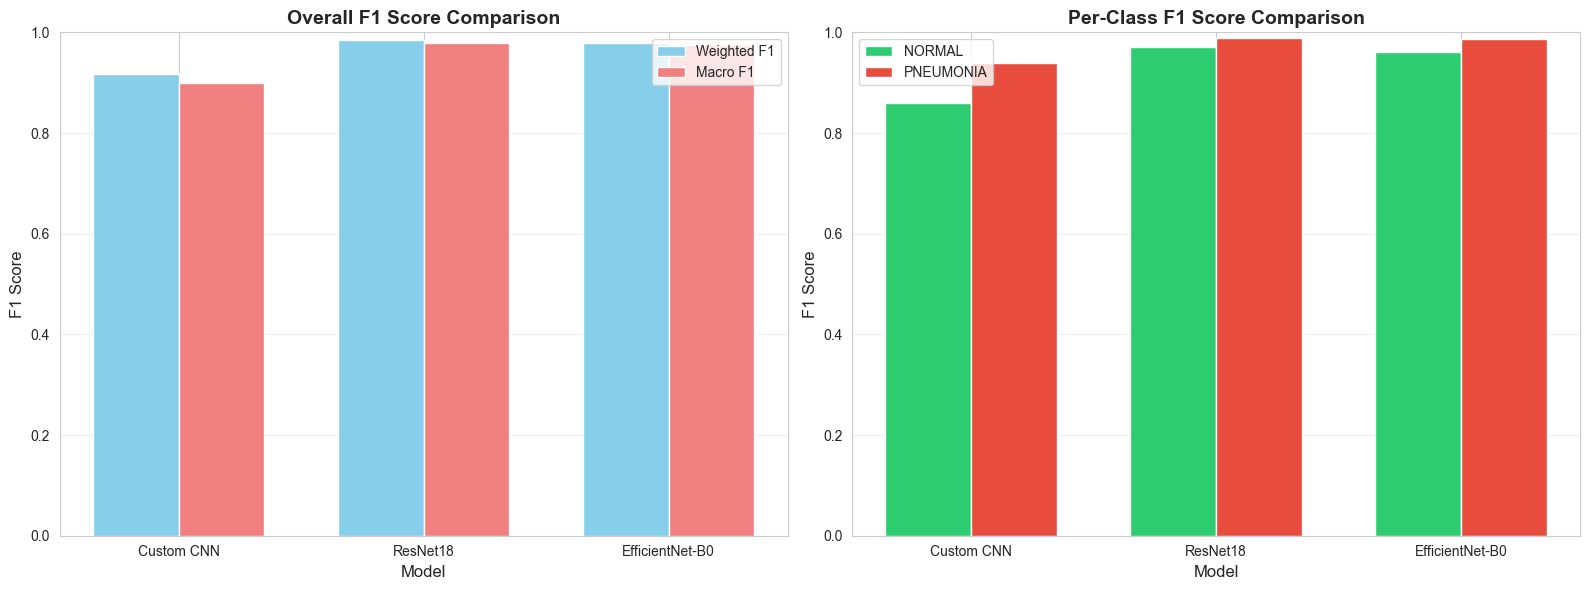

In [87]:
# Bar chart comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Weighted and Macro F1
x = np.arange(len(comparison_df))
width = 0.35

axes[0].bar(x - width/2, comparison_df['Weighted F1'], width, label='Weighted F1', color='skyblue')
axes[0].bar(x + width/2, comparison_df['Macro F1'], width, label='Macro F1', color='lightcoral')
axes[0].set_xlabel('Model', fontsize=12)
axes[0].set_ylabel('F1 Score', fontsize=12)
axes[0].set_title('Overall F1 Score Comparison', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison_df['Model'])
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0, 1.0])

# Per-class F1
axes[1].bar(x - width/2, comparison_df['NORMAL F1'], width, label='NORMAL', color='#2ecc71')
axes[1].bar(x + width/2, comparison_df['PNEUMONIA F1'], width, label='PNEUMONIA', color='#e74c3c')
axes[1].set_xlabel('Model', fontsize=12)
axes[1].set_ylabel('F1 Score', fontsize=12)
axes[1].set_title('Per-Class F1 Score Comparison', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison_df['Model'])
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_ylim([0, 1.0])

plt.tight_layout()
plt.show()

## Task 3: GradCAM

In [88]:
# Initialize models
model_cnn = CustomCNN(num_classes=2).to(device)
model_resnet = models.resnet18(pretrained=False)
num_features = model_resnet.fc.in_features
model_resnet.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 128),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(128, 2)
)
model_resnet = model_resnet.to(device)

model_efficient = models.efficientnet_b0(pretrained=False)
num_features = model_efficient.classifier[1].in_features
model_efficient.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(256, 2)
)
model_efficient = model_efficient.to(device)

# Load trained weights
try:
    model_cnn.load_state_dict(torch.load('custom_cnn_pneumonia_full.pth', map_location=device))
    model_resnet.load_state_dict(torch.load('resnet18_pneumonia_full.pth', map_location=device))
    model_efficient.load_state_dict(torch.load('efficientnet_b0_pneumonia_full.pth', map_location=device))
    print("✓ All models loaded successfully!")
except FileNotFoundError as e:
    print(f"⚠ Warning: Could not find model weights. Please train models first.")
    print(f"   Error: {e}")

# Set models to evaluation mode
model_cnn.eval()
model_resnet.eval()
model_efficient.eval()

print("✓ Models set to evaluation mode")

/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


✓ All models loaded successfully!
✓ Models set to evaluation mode


In [121]:
def set_inplace_false(model):
    """
    Recursively set inplace=False for all activation layers.
    This fixes Grad-CAM in-place operation errors.
    """
    count = 0
    for module in model.modules():
        if isinstance(module, nn.ReLU):
            module.inplace = False
            count += 1
        elif isinstance(module, nn.ReLU6):
            module.inplace = False
            count += 1
        elif isinstance(module, nn.LeakyReLU):
            module.inplace = False
            count += 1
        elif isinstance(module, nn.ELU):
            module.inplace = False
            count += 1
        elif isinstance(module, nn.CELU):
            module.inplace = False
            count += 1
        elif isinstance(module, nn.SELU):
            module.inplace = False
            count += 1
        elif hasattr(module, 'inplace'):
            try:
                module.inplace = False
                count += 1
            except:
                pass
    return model, count

# Apply to all models
print("Disabling in-place operations in all models...\n")

model_cnn, count_cnn = set_inplace_false(model_cnn)
print(f"Custom CNN: {count_cnn} layers modified")

model_resnet, count_resnet = set_inplace_false(model_resnet)
print(f"ResNet18: {count_resnet} layers modified")

model_efficient, count_efficient = set_inplace_false(model_efficient)
print(f"EfficientNet-B0: {count_efficient} layers modified")

print("All in-place operations disabled!")


Disabling in-place operations in all models...

Custom CNN: 11 layers modified
ResNet18: 12 layers modified
EfficientNet-B0: 52 layers modified
All in-place operations disabled!


In [93]:
class GradCAM:
    """Grad-CAM implementation for PyTorch models.
    
    Reference:
    Selvaraju et al., "Grad-CAM: Visual Explanations from Deep Networks 
    via Gradient-based Localization", ICCV 2017
    """
    
    def __init__(self, model, target_layer):
        """
        Args:
            model: PyTorch model
            target_layer: The convolutional layer to extract gradients from
        """
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register hooks
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)
    
    def save_activation(self, module, input, output):
        """Hook to save forward pass activations."""
        self.activations = output.detach().clone()
    
    def save_gradient(self, module, grad_input, grad_output):
        """Hook to save backward pass gradients."""
        self.gradients = grad_output[0].detach().clone()
    
    def generate_cam(self, input_image, target_class=None):
        """
        Generate Grad-CAM heatmap.
        
        Args:
            input_image: Input tensor [1, C, H, W]
            target_class: Target class index (if None, uses predicted class)
        
        Returns:
            cam: Normalized heatmap [H, W]
            prediction: Model prediction
        """
        # Ensure input requires grad
        input_image = input_image.clone().requires_grad_(True)
        
        # Forward pass
        self.model.eval()
        output = self.model(input_image)
        
        # Get predicted class if not specified
        if target_class is None:
            target_class = output.argmax(dim=1).item()
        
        # Backward pass
        self.model.zero_grad()
        class_score = output[0, target_class]
        class_score.backward(retain_graph=True)
        
        # Generate CAM
        # Global average pooling of gradients
        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        
        # Weighted combination of activation maps
        cam = torch.sum(weights * self.activations, dim=1).squeeze()
        
        # Apply ReLU (only positive contributions)
        cam = F.relu(cam)
        
        # Normalize to [0, 1]
        cam_min = cam.min()
        cam_max = cam.max()
        if cam_max - cam_min > 1e-8:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = torch.zeros_like(cam)
        
        return cam.cpu().numpy(), output.detach()

print("✓ Grad-CAM class defined")

✓ Grad-CAM class defined


In [ ]:
def get_target_layers(model, model_name):
    """Get the appropriate target layer for each model."""
    if model_name == "Custom CNN":
        return model.conv4[-2]  # Last conv layer before pooling
    elif model_name == "ResNet18":
        return model.layer4[-1]  # Last residual block
    elif model_name == "EfficientNet-B0":
        return model.features[-1]  # Last feature layer
    else:
        raise ValueError(f"Unknown model: {model_name}")


def apply_colormap_on_image(org_img, activation_map, colormap=cv2.COLORMAP_JET):
    """
    Apply a colormap on the activation map and overlay it on the original image.
    """
    # Resize activation map to match image size
    heatmap = cv2.resize(activation_map, (org_img.shape[1], org_img.shape[0]))
    
    # Convert to uint8
    heatmap = np.uint8(255 * heatmap)
    
    # Apply colormap
    heatmap = cv2.applyColorMap(heatmap, colormap)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    
    # Normalize original image to [0, 255]
    if org_img.max() <= 1.0:
        org_img = np.uint8(255 * org_img)
    
    # Overlay heatmap on original image
    superimposed = cv2.addWeighted(org_img, 0.6, heatmap, 0.4, 0)
    
    return heatmap, superimposed


def denormalize_image(img_tensor):
    """
    Denormalize an image tensor.
   
    """
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    img = img_tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    return img


def visualize_gradcam(image_tensor, cam, prediction, true_label, class_names, model_name):
    """
    Visualize Grad-CAM results.

    """
    # Denormalize image
    img = denormalize_image(image_tensor[0])
    img_uint8 = np.uint8(255 * img)
    
    # Apply colormap
    heatmap, superimposed = apply_colormap_on_image(img_uint8, cam)
    
    # Get prediction probabilities
    probs = F.softmax(prediction, dim=1)[0]
    pred_class = prediction.argmax(dim=1).item()
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img)
    axes[0].set_title('Original Image', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # Heatmap
    axes[1].imshow(heatmap)
    axes[1].set_title('Grad-CAM Heatmap', fontsize=12, fontweight='bold')
    axes[1].axis('off')
    
    # Superimposed
    axes[2].imshow(superimposed)
    axes[2].set_title('Grad-CAM Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')
    
    # Add prediction info
    pred_text = f"Predicted: {class_names[pred_class]} ({probs[pred_class]:.2%})\n"
    pred_text += f"True Label: {class_names[true_label]}\n"
    pred_text += f"Correct: {'✓' if pred_class == true_label else '✗'}"
    
    fig.suptitle(f'{model_name} - Grad-CAM Visualization\n{pred_text}', 
                 fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

print("Utility functions defined")

✓ Utility functions defined


In [111]:
# Create a dataloader with batch_size=1 for visualization
single_test_loader = DataLoader(
    test_dataset,
    batch_size=1,  # Single image at a time
    shuffle=True,
    num_workers=0
)

In [122]:
def find_prediction_categories(model, test_loader, class_names, device='cuda'):
    """
    Find examples of TP, FP, TN, FN from test set.
    """
    model.eval()
    
    categories = {
        'true_positive': [],    # Predicted PNEUMONIA, Actually PNEUMONIA
        'false_positive': [],   # Predicted PNEUMONIA, Actually NORMAL
        'true_negative': [],    # Predicted NORMAL, Actually NORMAL
        'false_negative': []    # Predicted NORMAL, Actually PNEUMONIA
    }
    
    NORMAL = 0
    PNEUMONIA = 1
    
    print("Searching for examples in test set...")
    
    with torch.no_grad():
        for images, labels in tqdm(test_loader):
            images = images.to(device)
            labels = labels.to(device)
            
            # Get predictions
            outputs = model(images)
            _, predictions = torch.max(outputs, 1)
            
            # Check each image in batch
            for i in range(len(images)):
                img = images[i:i+1]
                label = labels[i].item()
                pred = predictions[i].item()
                
                # True Positive: Predicted PNEUMONIA (1), Actually PNEUMONIA (1)
                if pred == PNEUMONIA and label == PNEUMONIA:
                    if len(categories['true_positive']) < 10:  # Store up to 10 examples
                        categories['true_positive'].append((img, label, pred))
                
                # False Positive: Predicted PNEUMONIA (1), Actually NORMAL (0)
                elif pred == PNEUMONIA and label == NORMAL:
                    if len(categories['false_positive']) < 10:
                        categories['false_positive'].append((img, label, pred))
                
                # True Negative: Predicted NORMAL (0), Actually NORMAL (0)
                elif pred == NORMAL and label == NORMAL:
                    if len(categories['true_negative']) < 10:
                        categories['true_negative'].append((img, label, pred))
                
                # False Negative: Predicted NORMAL (0), Actually PNEUMONIA (1)
                elif pred == NORMAL and label == PNEUMONIA:
                    if len(categories['false_negative']) < 10:
                        categories['false_negative'].append((img, label, pred))
            
            # Stop early if we have enough examples
            if all(len(v) >= 1 for v in categories.values()):
                break
    
    # Print statistics
    print("Found examples:")
    for category, examples in categories.items():
        print(f"{category.replace('_', ' ').title()}: {len(examples)} examples")
    
    return categories


def visualize_prediction_category(model, model_name, image, true_label, pred_label, 
                                   class_names, category_name, device='cuda'):
    """
    Visualize a single prediction category with Grad-CAM.
    """
    # Get target layer
    target_layer = get_target_layers(model, model_name)
    
    # Initialize Grad-CAM
    grad_cam = GradCAM(model, target_layer)
    
    # Generate CAM
    cam, prediction = grad_cam.generate_cam(image)
    
    # Denormalize image
    img = denormalize_image(image[0])
    img_uint8 = np.uint8(255 * img)
    
    # Apply colormap
    heatmap, superimposed = apply_colormap_on_image(img_uint8, cam)
    
    # Get prediction probabilities
    probs = F.softmax(prediction, dim=1)[0]
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img)
    axes[0].set_title('Original X-ray', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # Heatmap
    axes[1].imshow(heatmap)
    axes[1].set_title('Grad-CAM Heatmap', fontsize=12, fontweight='bold')
    axes[1].axis('off')
    
    # Superimposed
    axes[2].imshow(superimposed)
    axes[2].set_title('Grad-CAM Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')
    
    # Add detailed prediction info
    pred_text = f"{category_name}\n\n"
    pred_text += f"Model: {model_name}\n"
    pred_text += f"Predicted: {class_names[pred_label]} ({probs[pred_label]:.2%})\n"
    pred_text += f"Actual: {class_names[true_label]}\n\n"
    pred_text += f"Confidence Scores:\n"
    for i, name in enumerate(class_names):
        pred_text += f"  {name}: {probs[i]:.2%}\n"
    
    # Color code based on correctness
    if pred_label == true_label:
        title_color = 'green'
        result = "✓ CORRECT"
    else:
        title_color = 'red'
        result = "✗ INCORRECT"
    
    fig.suptitle(f'{result} - {category_name}\n{pred_text}', 
                 fontsize=14, fontweight='bold', color=title_color)
    
    plt.tight_layout()
    plt.show()


def create_report_visualizations(model, model_name, test_loader, class_names, device='cuda'):
    """
    Create all four required visualizations for the report:
    True Positive, False Positive, True Negative, False Negative
    """
    print(f"Creating Report Visualizations for {model_name}")
   
    # Find examples
    categories = find_prediction_categories(model, test_loader, class_names, device)
    
    # Category explanations
    category_info = {
        'true_positive': {
            'name': 'True Positive (TP)',
            'description': 'Model correctly identified PNEUMONIA'
        },
        'false_positive': {
            'name': 'False Positive (FP)',
            'description': 'Model incorrectly predicted PNEUMONIA (actually NORMAL)'
        },
        'true_negative': {
            'name': 'True Negative (TN)',
            'description': 'Model correctly identified NORMAL'
        },
        'false_negative': {
            'name': 'False Negative (FN)',
            'description': 'Model incorrectly predicted NORMAL (actually PNEUMONIA)'
        }
    }
    
    # Visualize one example from each category
    for category_key, info in category_info.items():
        if len(categories[category_key]) > 0:
            print(f"\n{info['name']}: {info['description']}")
            print("-" * 70)
            
            # Get first example
            image, true_label, pred_label = categories[category_key][0]
            
            # Visualize
            visualize_prediction_category(
                model, model_name, image, true_label, pred_label,
                class_names, info['name'], device
            )
        else:
            print(f"\n⚠ Warning: No {info['name']} examples found!")
    
    print("All report visualizations complete!")
    
    return categories

Creating Report Visualizations for Custom CNN
Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
100%|██████████| 71/71 [01:38<00:00,  1.39s/it]


Found examples:
True Positive: 10 examples
False Positive: 10 examples
True Negative: 0 examples
False Negative: 0 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1671366279.py:128: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


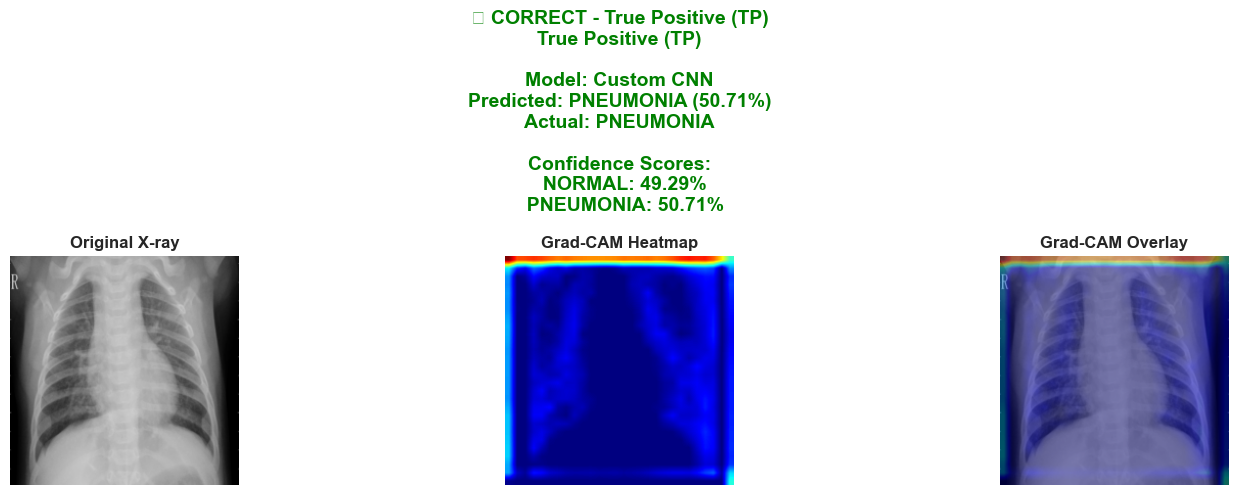


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1671366279.py:128: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


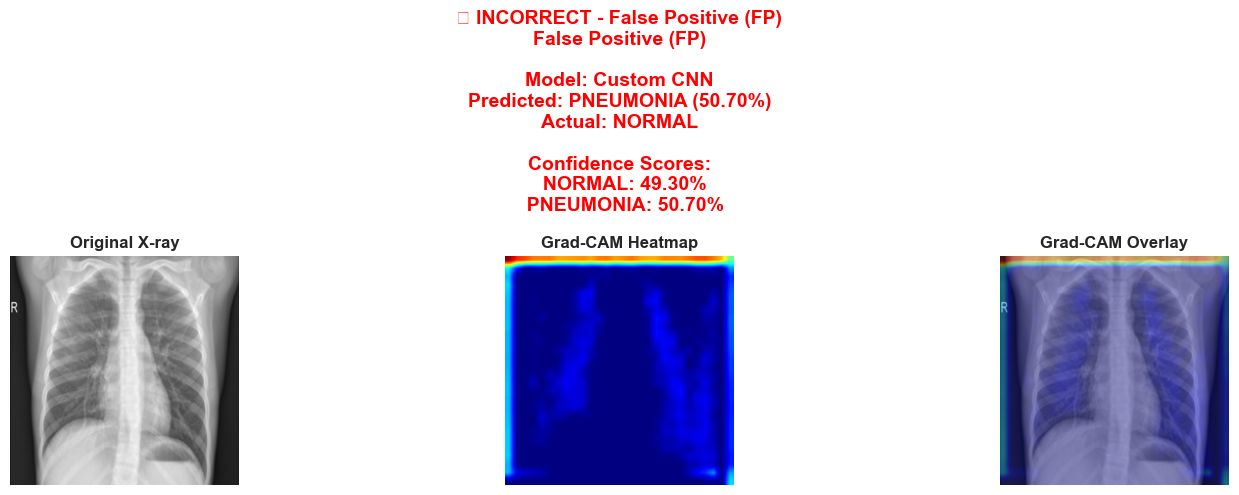


⚠ Warning: No True Negative (TN) examples found!

⚠ Warning: No False Negative (FN) examples found!
All report visualizations complete!


In [123]:
class_names=["NORMAL","PNEUMONIA"]
categories_cnn = create_report_visualizations(
    model_cnn, "Custom CNN", test_loader, class_names, device
)


Creating Report Visualizations for ResNet18

Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
 32%|███▏      | 23/71 [01:29<03:07,  3.91s/it]



Found examples:
True Positive: 10 examples
False Positive: 10 examples
True Negative: 10 examples
False Negative: 2 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/408669685.py:145: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


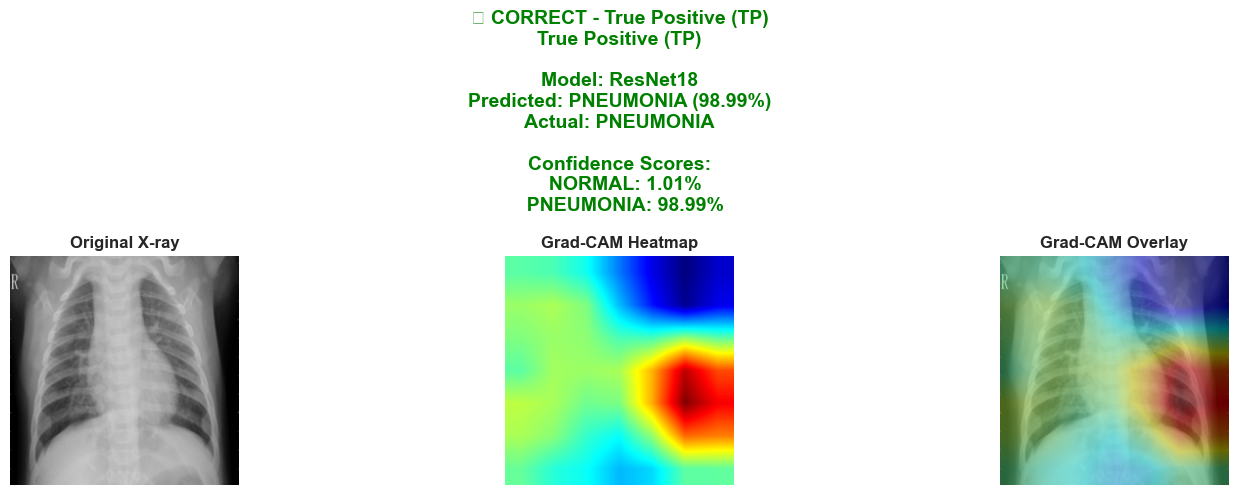


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/408669685.py:145: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


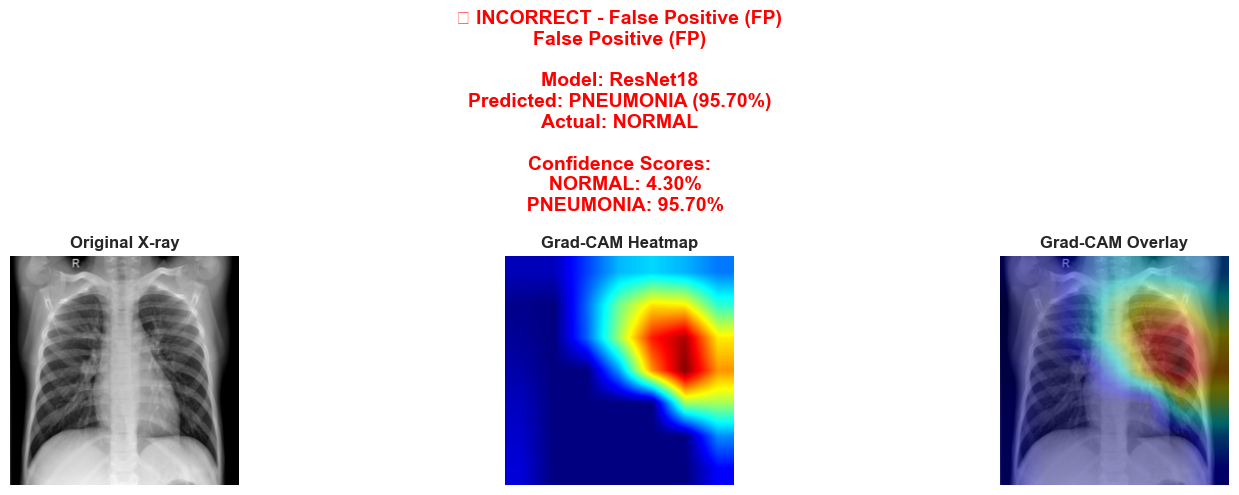


True Negative (TN): Model correctly identified NORMAL
----------------------------------------------------------------------


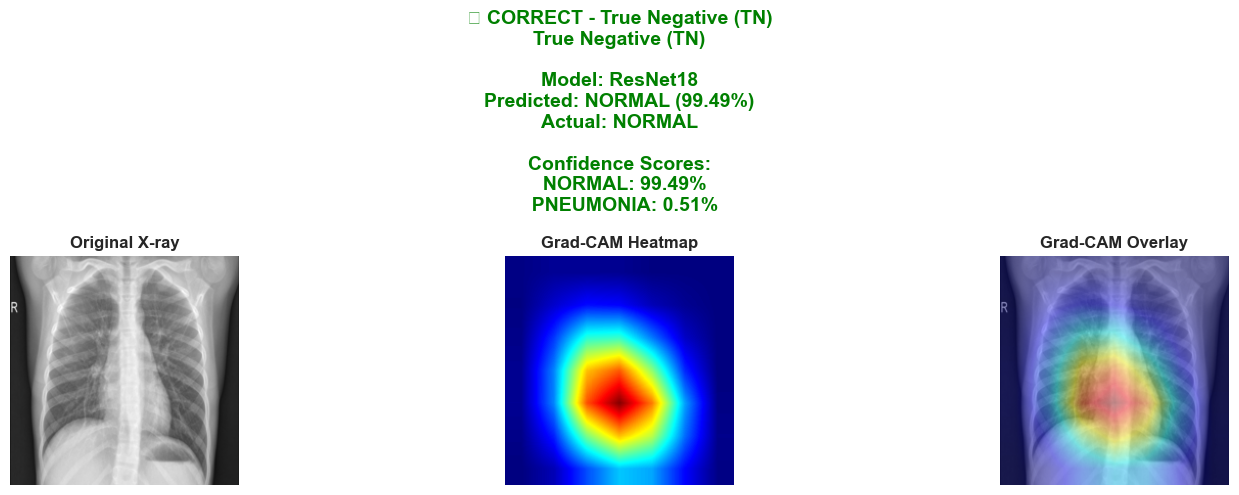


False Negative (FN): Model incorrectly predicted NORMAL (actually PNEUMONIA)
----------------------------------------------------------------------


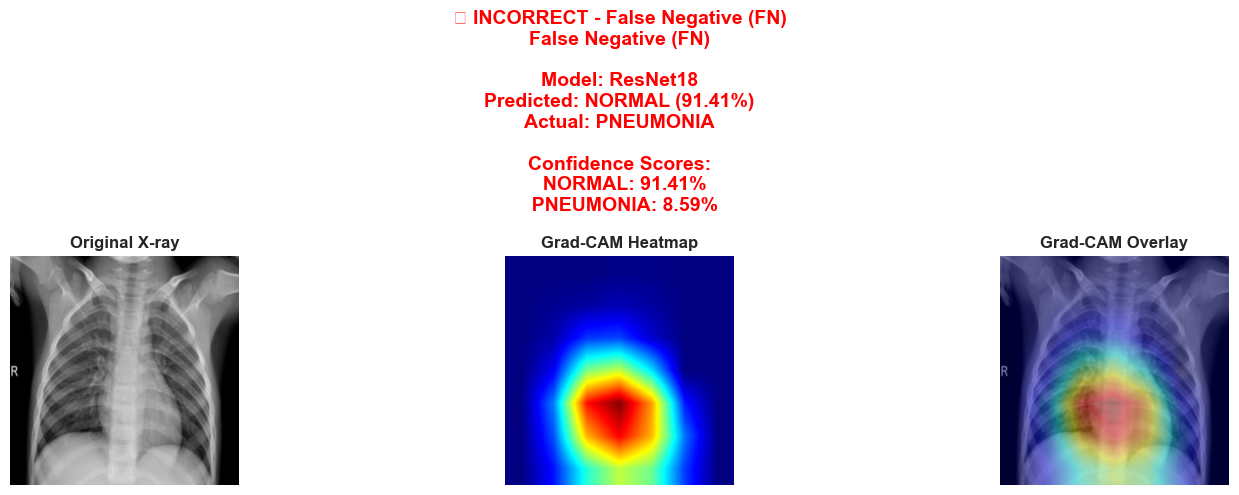


All report visualizations complete!



In [104]:
categories_resnet=create_report_visualizations(model_resnet, "ResNet18", test_loader, class_names, device)


Creating Report Visualizations for EfficientNet-B0

Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
 27%|██▋       | 19/71 [01:30<04:06,  4.75s/it]



Found examples:
True Positive: 10 examples
False Positive: 10 examples
True Negative: 10 examples
False Negative: 1 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/408669685.py:145: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


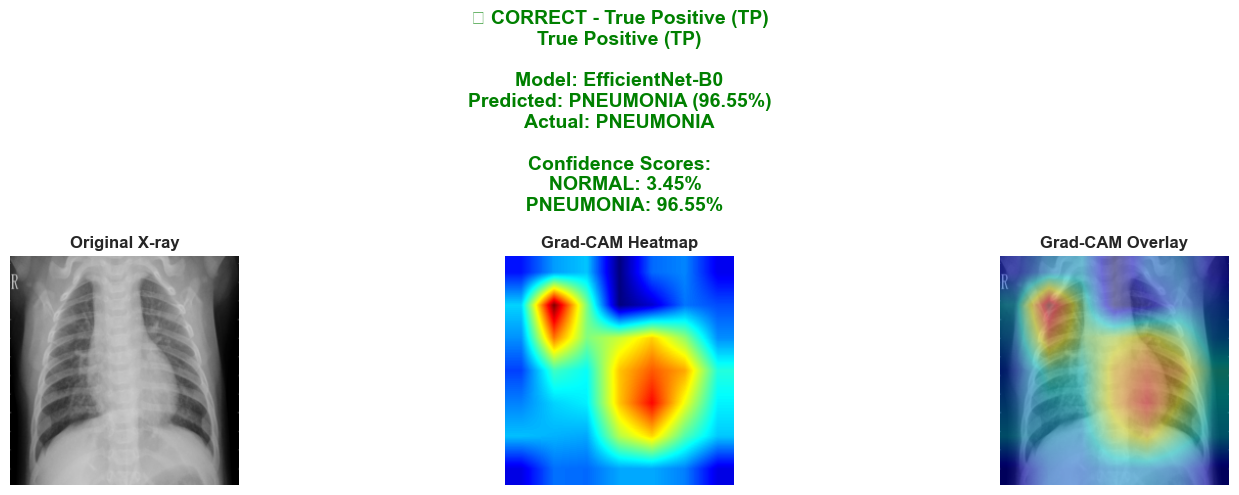


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------


/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/408669685.py:145: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


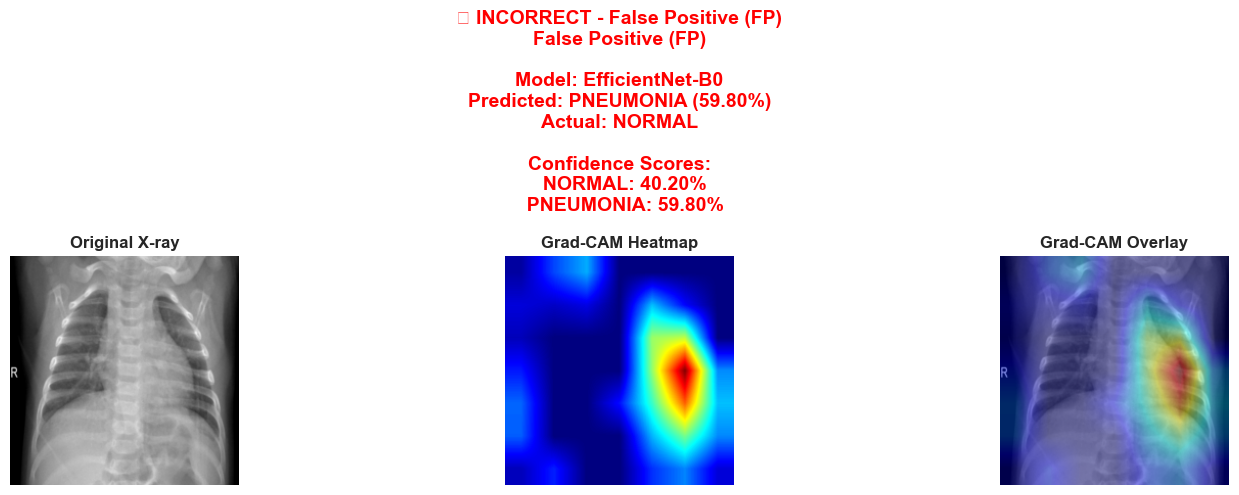


True Negative (TN): Model correctly identified NORMAL
----------------------------------------------------------------------


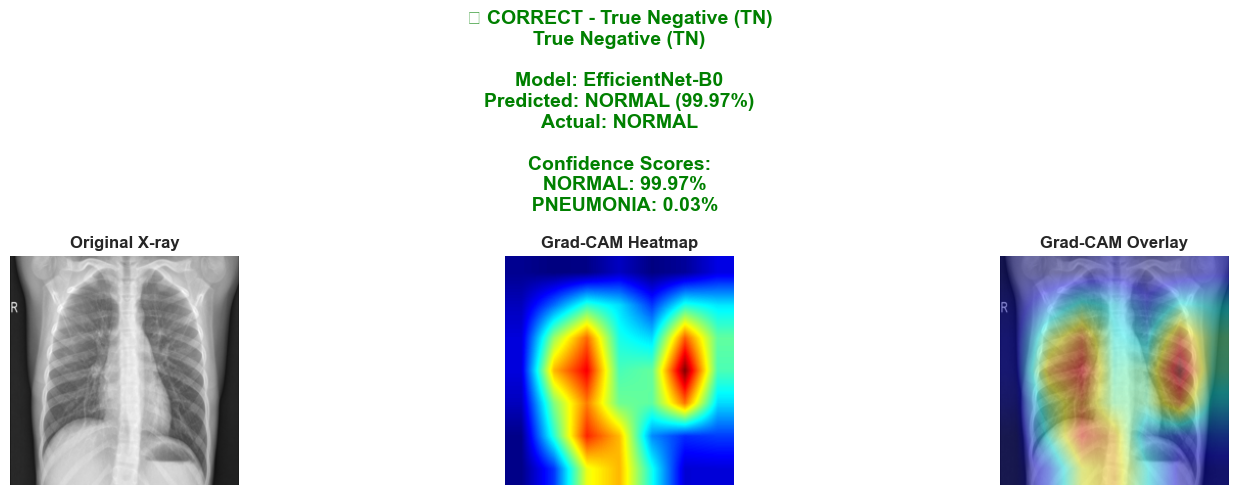


False Negative (FN): Model incorrectly predicted NORMAL (actually PNEUMONIA)
----------------------------------------------------------------------


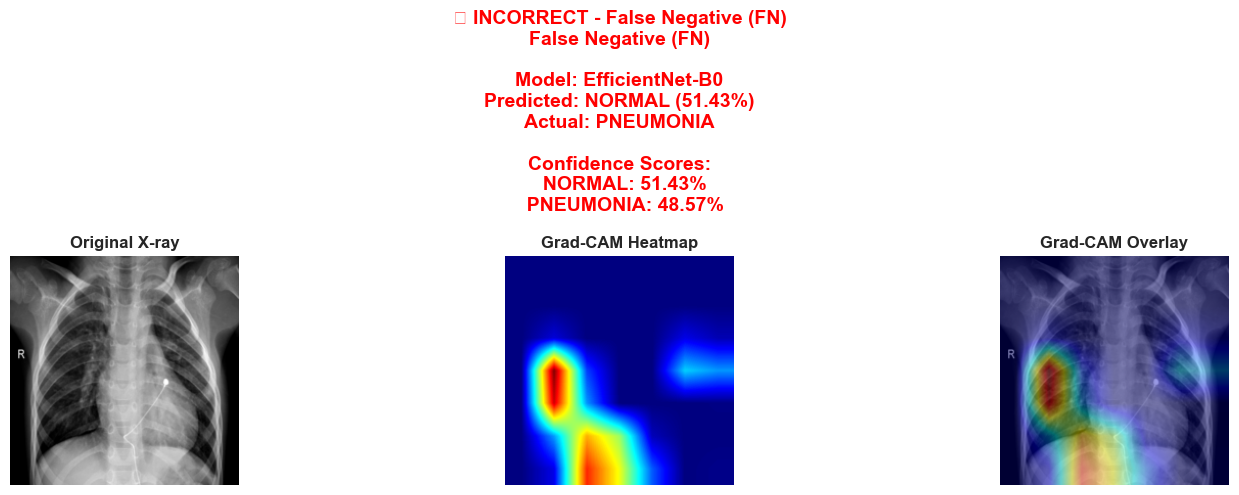


All report visualizations complete!



In [105]:
categories_efficientnet = create_report_visualizations(model_efficient, "EfficientNet-B0", test_loader, class_names, device)

## Task 5: RISE Method

In [106]:
class RISE:
    """RISE: Randomized Input Sampling for Explanation.
    
    Reference:
    Petsiuk et al., "RISE: Randomized Input Sampling for Explanation 
    of Black-box Models", BMVC 2018
    """
    
    def __init__(self, model, input_size=(224, 224)):
        self.model = model
        self.model.eval()
        self.input_size = input_size
    
    def generate_masks(self, num_masks=2000, mask_prob=0.5, mask_size=(7, 7)):
        """
        Generate random binary masks.
        
        Args:
            num_masks: Number of random masks to generate
            mask_prob: Probability of each cell being 1
            mask_size: Size of the low-resolution mask grid
        
        Returns:
            masks: Tensor of masks [num_masks, 1, H, W]
        """
        # Generate random masks at low resolution
        masks = torch.bernoulli(torch.ones(num_masks, 1, *mask_size) * mask_prob)
        
        # Upsample to input size
        masks = F.interpolate(masks, size=self.input_size, mode='bilinear', align_corners=False)
        
        return masks
    
    def generate_saliency_map(self, input_image, target_class=None, 
                              num_masks=2000, batch_size=50):
        """
        Generate RISE saliency map.
        
        Args:
            input_image: Input tensor [1, C, H, W]
            target_class: Target class index (if None, uses predicted class)
            num_masks: Number of random masks to use
            batch_size: Batch size for processing masks
        
        Returns:
            saliency_map: RISE saliency map [H, W]
            prediction: Model prediction on original image
        """
        # Get original prediction
        with torch.no_grad():
            output = self.model(input_image)
            original_probs = F.softmax(output, dim=1)
        
        if target_class is None:
            target_class = output.argmax(dim=1).item()
        
        # Generate masks
        print(f"Generating {num_masks} random masks...")
        masks = self.generate_masks(num_masks=num_masks)
        masks = masks.to(input_image.device)
        
        # Initialize saliency map
        saliency_map = torch.zeros(self.input_size).to(input_image.device)
        
        # Process masks in batches
        print(f"Processing masks in batches of {batch_size}...")
        num_batches = (num_masks + batch_size - 1) // batch_size
        
        for i in tqdm(range(num_batches)):
            start_idx = i * batch_size
            end_idx = min((i + 1) * batch_size, num_masks)
            
            # Get batch of masks
            batch_masks = masks[start_idx:end_idx]
            
            # Apply masks to input image
            masked_images = input_image * batch_masks
            
            # Get predictions
            with torch.no_grad():
                batch_outputs = self.model(masked_images)
                batch_probs = F.softmax(batch_outputs, dim=1)
                target_probs = batch_probs[:, target_class]
            
            # Accumulate weighted masks
            for j in range(len(target_probs)):
                saliency_map += target_probs[j] * batch_masks[j].squeeze()
        
        # Normalize by number of masks
        saliency_map = saliency_map / num_masks
        
        # Convert to numpy and normalize to [0, 1]
        saliency_map = saliency_map.cpu().numpy()
        if saliency_map.max() > saliency_map.min():
            saliency_map = (saliency_map - saliency_map.min()) / \
                          (saliency_map.max() - saliency_map.min())
        
        return saliency_map, output

print("✓ RISE class defined")

✓ RISE class defined


In [107]:
# ============================================================================
# RISE Visualization Functions
# ============================================================================

def visualize_rise_category(model, model_name, image, true_label, pred_label, 
                            class_names, category_name, device='cuda', 
                            num_masks=1000, batch_size=50):
    """
    Visualize a single prediction category with RISE.
    
    Args:
        model: PyTorch model
        model_name: Name of the model
        image: Image tensor [1, C, H, W]
        true_label: Ground truth label
        pred_label: Predicted label
        class_names: List of class names
        category_name: Name of category (e.g., "True Positive")
        device: Device to use
        num_masks: Number of random masks for RISE
        batch_size: Batch size for processing masks
    """
    # Initialize RISE
    rise = RISE(model, input_size=(224, 224))
    
    # Generate RISE saliency map
    print(f"  Generating RISE saliency map for {category_name}...")
    rise_saliency, prediction = rise.generate_saliency_map(
        image, 
        num_masks=num_masks,
        batch_size=batch_size
    )
    
    # Denormalize image
    img = denormalize_image(image[0])
    img_uint8 = np.uint8(255 * img)
    
    # Apply colormap
    heatmap = np.uint8(255 * rise_saliency)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    
    # Resize heatmap to match image size
    heatmap = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
    
    # Create overlay
    superimposed = cv2.addWeighted(img_uint8, 0.6, heatmap, 0.4, 0)
    
    # Get prediction probabilities
    probs = F.softmax(prediction, dim=1)[0]
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img)
    axes[0].set_title('Original X-ray', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # Heatmap
    axes[1].imshow(heatmap)
    axes[1].set_title('RISE Saliency Map', fontsize=12, fontweight='bold')
    axes[1].axis('off')
    
    # Superimposed
    axes[2].imshow(superimposed)
    axes[2].set_title('RISE Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')
    
    # Add detailed prediction info
    pred_text = f"{category_name}\n\n"
    pred_text += f"Model: {model_name}\n"
    pred_text += f"Predicted: {class_names[pred_label]} ({probs[pred_label]:.2%})\n"
    pred_text += f"Actual: {class_names[true_label]}\n\n"
    pred_text += f"Confidence Scores:\n"
    for i, name in enumerate(class_names):
        pred_text += f"  {name}: {probs[i]:.2%}\n"
    
    # Color code based on correctness
    if pred_label == true_label:
        title_color = 'green'
        result = "✓ CORRECT"
    else:
        title_color = 'red'
        result = "✗ INCORRECT"
    
    fig.suptitle(f'{result} - {category_name} (RISE)\n{pred_text}', 
                 fontsize=14, fontweight='bold', color=title_color)
    
    plt.tight_layout()
    plt.show()


def create_rise_report_visualizations(model, model_name, test_loader, class_names, 
                                      device='cuda', num_masks=1000, batch_size=50):
    """
    Create all four RISE visualizations for the report:
    True Positive, False Positive, True Negative, False Negative
    """
    print(f"\n{'='*70}")
    print(f"Creating RISE Report Visualizations for {model_name}")
    print(f"{'='*70}\n")
    
    # Find examples
    categories = find_prediction_categories(model, test_loader, class_names, device)
    
    # Category explanations
    category_info = {
        'true_positive': {
            'name': 'True Positive (TP)',
            'description': 'Model correctly identified PNEUMONIA'
        },
        'false_positive': {
            'name': 'False Positive (FP)',
            'description': 'Model incorrectly predicted PNEUMONIA (actually NORMAL)'
        },
        'true_negative': {
            'name': 'True Negative (TN)',
            'description': 'Model correctly identified NORMAL'
        },
        'false_negative': {
            'name': 'False Negative (FN)',
            'description': 'Model incorrectly predicted NORMAL (actually PNEUMONIA)'
        }
    }
    
    # Visualize one example from each category
    for category_key, info in category_info.items():
        if len(categories[category_key]) > 0:
            print(f"\n{info['name']}: {info['description']}")
            print("-" * 70)
            
            # Get first example
            image, true_label, pred_label = categories[category_key][0]
            
            # Visualize
            visualize_rise_category(
                model, model_name, image, true_label, pred_label,
                class_names, info['name'], device, num_masks, batch_size
            )
        else:
            print(f"\n⚠ Warning: No {info['name']} examples found!")
    
    print(f"\n{'='*70}")
    print("All RISE report visualizations complete!")
    print(f"{'='*70}\n")
    
    return categories


def save_rise_visualization(model, model_name, image, true_label, pred_label, 
                            class_names, category_name, save_path, device='cuda',
                            num_masks=1000, batch_size=50):
    """
    Save a single RISE visualization to file.
    """
    # Initialize RISE
    rise = RISE(model, input_size=(224, 224))
    
    # Generate RISE saliency map (suppress print output for cleaner saves)
    import sys
    from io import StringIO
    old_stdout = sys.stdout
    sys.stdout = StringIO()
    
    rise_saliency, prediction = rise.generate_saliency_map(
        image, 
        num_masks=num_masks,
        batch_size=batch_size
    )
    
    sys.stdout = old_stdout
    
    # Denormalize image
    img = denormalize_image(image[0])
    img_uint8 = np.uint8(255 * img)
    
    # Apply colormap
    heatmap = np.uint8(255 * rise_saliency)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    heatmap = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
    
    # Create overlay
    superimposed = cv2.addWeighted(img_uint8, 0.6, heatmap, 0.4, 0)
    
    # Get prediction probabilities
    probs = F.softmax(prediction, dim=1)[0]
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img)
    axes[0].set_title('Original X-ray', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    
    # Heatmap
    axes[1].imshow(heatmap)
    axes[1].set_title('RISE Saliency Map', fontsize=12, fontweight='bold')
    axes[1].axis('off')
    
    # Superimposed
    axes[2].imshow(superimposed)
    axes[2].set_title('RISE Overlay', fontsize=12, fontweight='bold')
    axes[2].axis('off')
    
    # Add prediction info
    pred_text = f"{category_name}\n\n"
    pred_text += f"Predicted: {class_names[pred_label]} ({probs[pred_label]:.2%})\n"
    pred_text += f"Actual: {class_names[true_label]}"
    
    # Color code
    if pred_label == true_label:
        title_color = 'green'
        result = "✓ CORRECT"
    else:
        title_color = 'red'
        result = "✗ INCORRECT"
    
    fig.suptitle(f'{model_name} - {result} (RISE)\n{pred_text}', 
                 fontsize=14, fontweight='bold', color=title_color)
    
    plt.tight_layout()
    
    # Save
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"✓ Saved: {save_path}")


def save_all_rise_visualizations(model, model_name, categories, class_names, 
                                 output_dir='report_figures_rise', device='cuda',
                                 num_masks=1000, batch_size=50):
    """
    Save all four RISE category visualizations for a model.
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    category_names = {
        'true_positive': 'True_Positive',
        'false_positive': 'False_Positive',
        'true_negative': 'True_Negative',
        'false_negative': 'False_Negative'
    }
    
    for category_key, category_name in category_names.items():
        if len(categories[category_key]) > 0:
            image, true_label, pred_label = categories[category_key][0]
            
            filename = f"{model_name.replace(' ', '_')}_RISE_{category_name}.png"
            save_path = os.path.join(output_dir, filename)
            
            print(f"  Generating {category_name}...")
            save_rise_visualization(
                model, model_name, image, true_label, pred_label,
                class_names, category_name.replace('_', ' '),
                save_path, device, num_masks, batch_size
            )

print("✓ RISE visualization functions defined")

✓ RISE visualization functions defined



Creating RISE Report Visualizations for Custom CNN

Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
 27%|██▋       | 19/71 [01:30<04:07,  4.77s/it]



Found examples:
True Positive: 10 examples
False Positive: 9 examples
True Negative: 10 examples
False Negative: 5 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------
  Generating RISE saliency map for True Positive (TP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.84it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


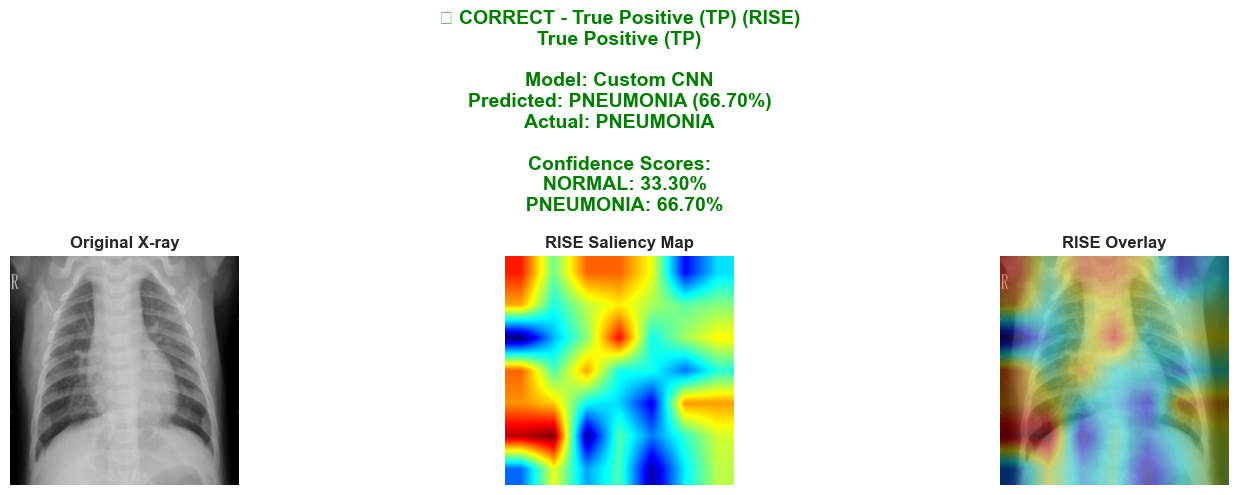


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------
  Generating RISE saliency map for False Positive (FP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  9.02it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


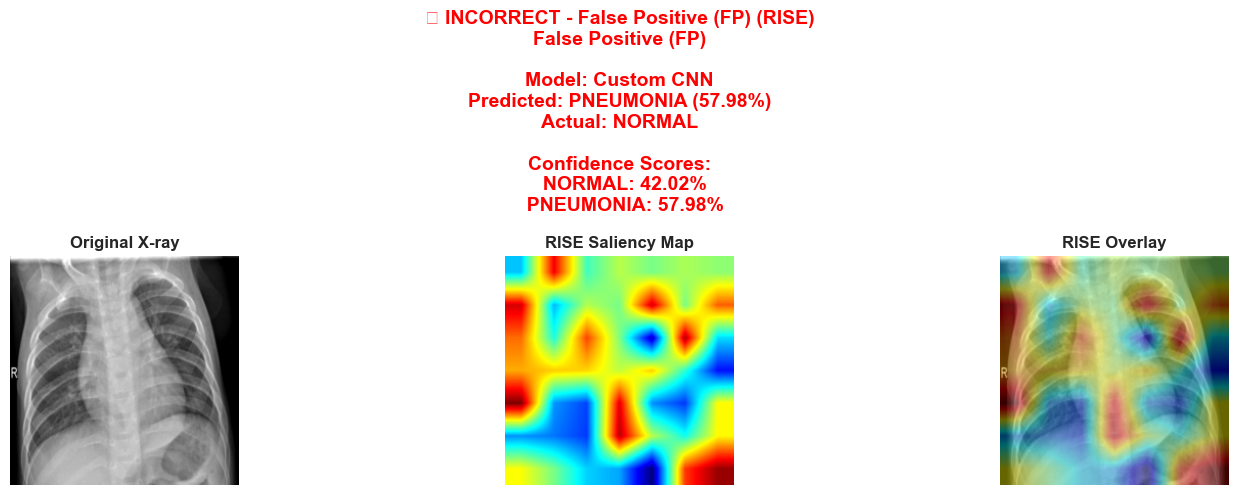


True Negative (TN): Model correctly identified NORMAL
----------------------------------------------------------------------
  Generating RISE saliency map for True Negative (TN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.97it/s]


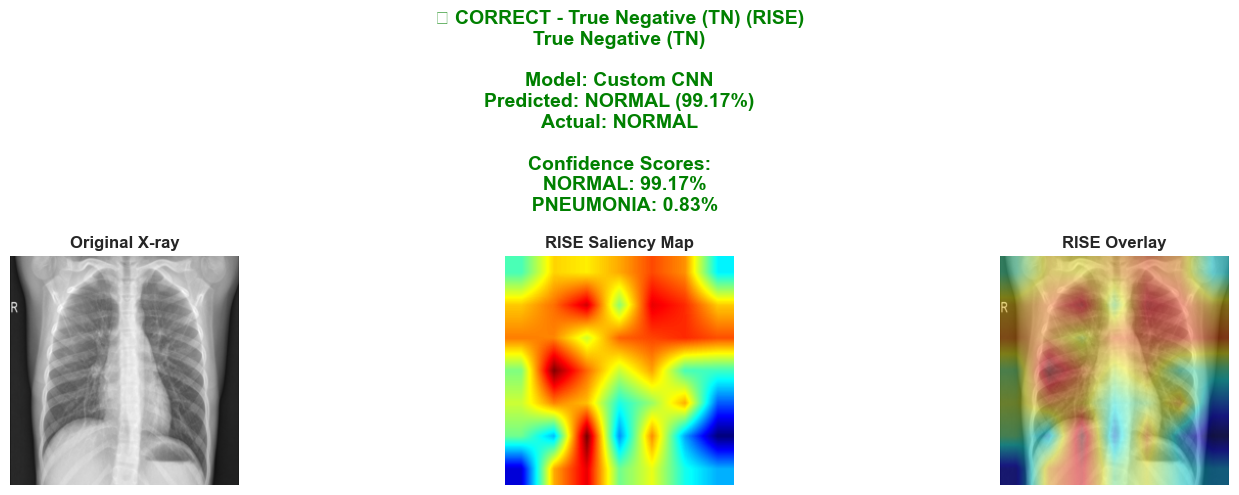


False Negative (FN): Model incorrectly predicted NORMAL (actually PNEUMONIA)
----------------------------------------------------------------------
  Generating RISE saliency map for False Negative (FN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.96it/s]


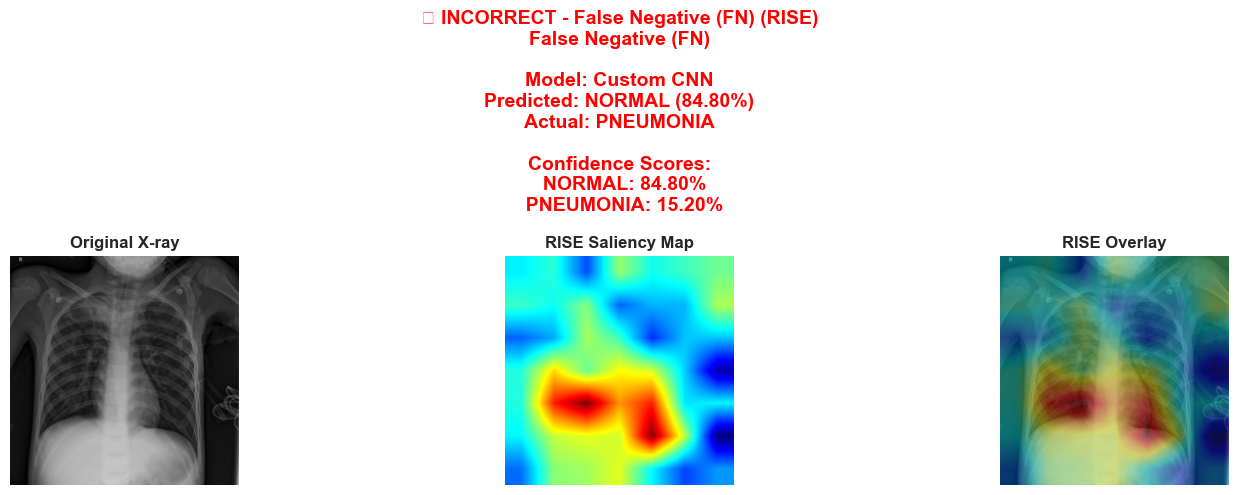


All RISE report visualizations complete!



In [108]:
categories_cnn_rise = create_rise_report_visualizations(
    model_cnn, "Custom CNN", test_loader, class_names, device)


Creating RISE Report Visualizations for ResNet18

Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
 32%|███▏      | 23/71 [01:30<03:08,  3.93s/it]



Found examples:
True Positive: 10 examples
False Positive: 10 examples
True Negative: 10 examples
False Negative: 2 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------
  Generating RISE saliency map for True Positive (TP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:01<00:00, 13.37it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


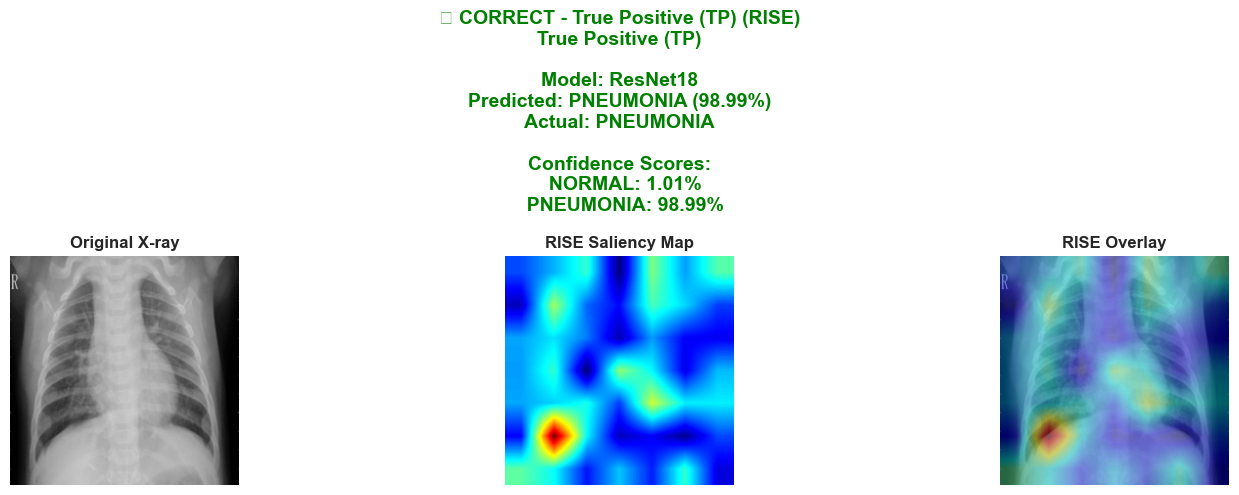


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------
  Generating RISE saliency map for False Positive (FP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:01<00:00, 13.83it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


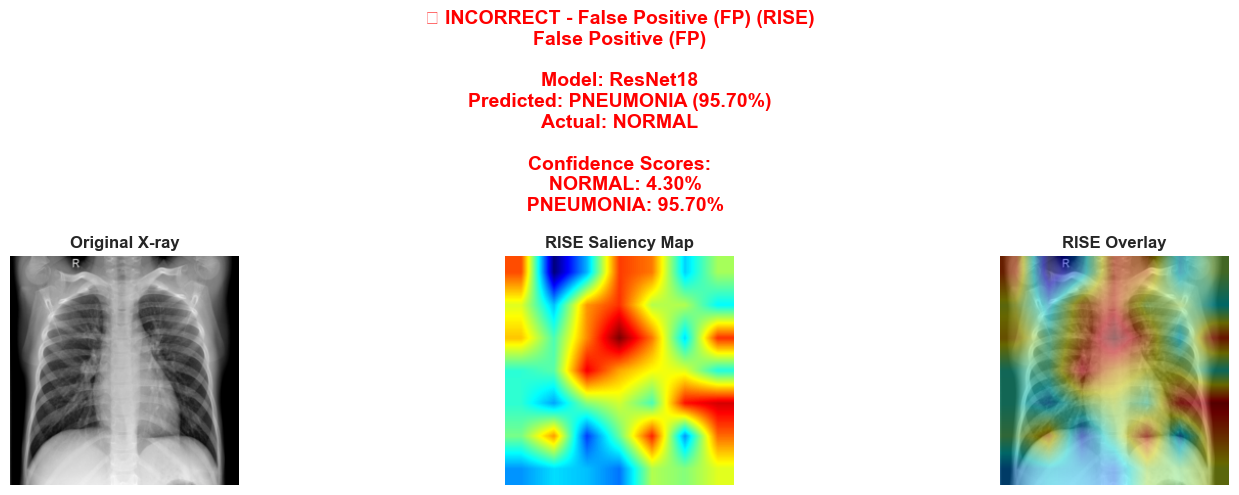


True Negative (TN): Model correctly identified NORMAL
----------------------------------------------------------------------
  Generating RISE saliency map for True Negative (TN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:01<00:00, 13.83it/s]


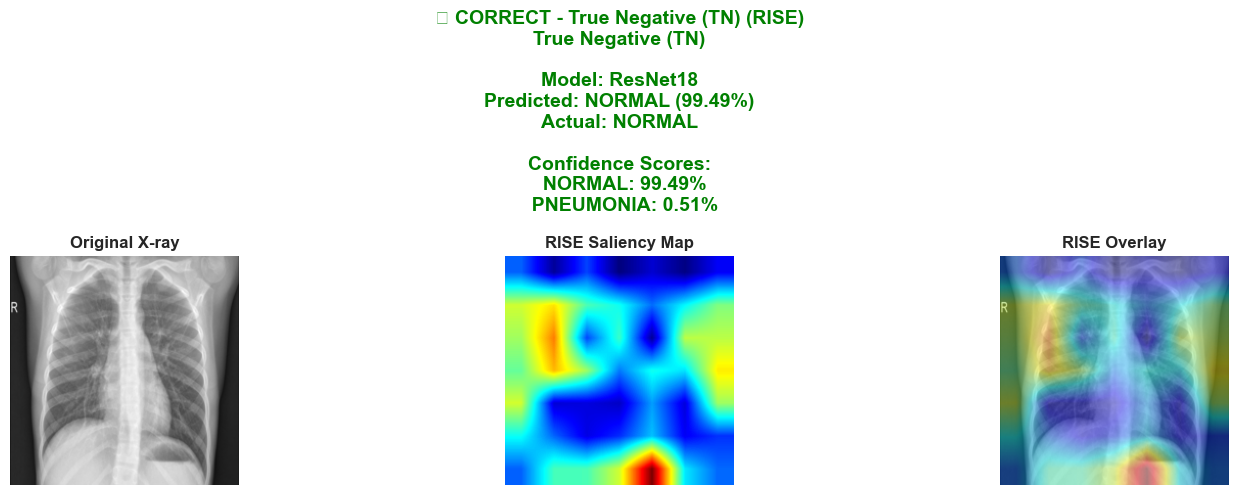


False Negative (FN): Model incorrectly predicted NORMAL (actually PNEUMONIA)
----------------------------------------------------------------------
  Generating RISE saliency map for False Negative (FN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:01<00:00, 13.77it/s]


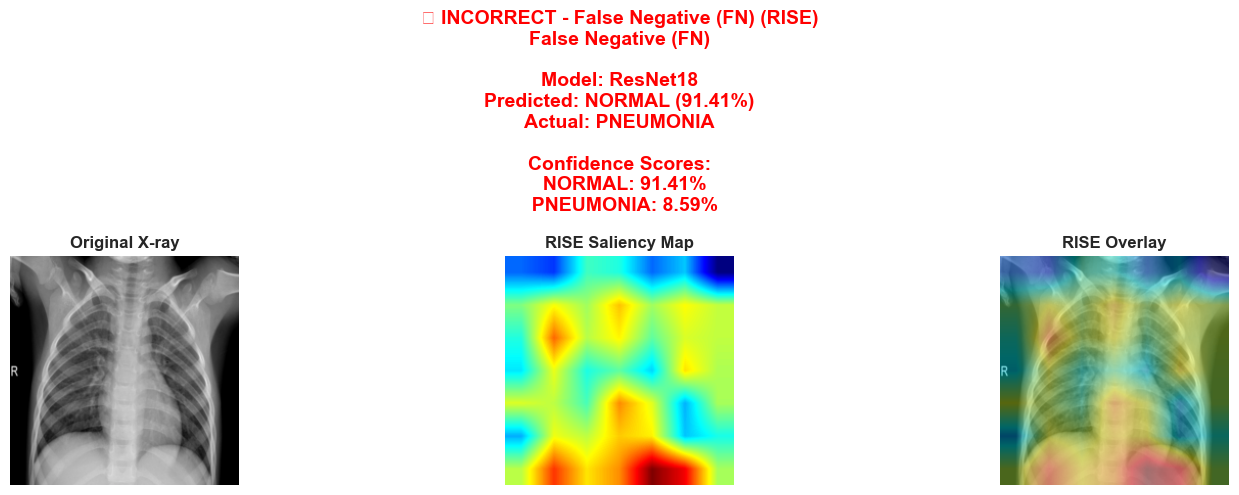


All RISE report visualizations complete!



In [109]:
categories_resnet_rise=create_rise_report_visualizations(model_resnet, "ResNet18", test_loader, class_names, device)


Creating RISE Report Visualizations for EfficientNet-B0

Searching for examples in test set...


  0%|          | 0/71 [00:00<?, ?it/s]/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 10 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
 27%|██▋       | 19/71 [01:30<04:08,  4.78s/it]



Found examples:
True Positive: 10 examples
False Positive: 10 examples
True Negative: 10 examples
False Negative: 1 examples

True Positive (TP): Model correctly identified PNEUMONIA
----------------------------------------------------------------------
  Generating RISE saliency map for True Positive (TP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  7.36it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


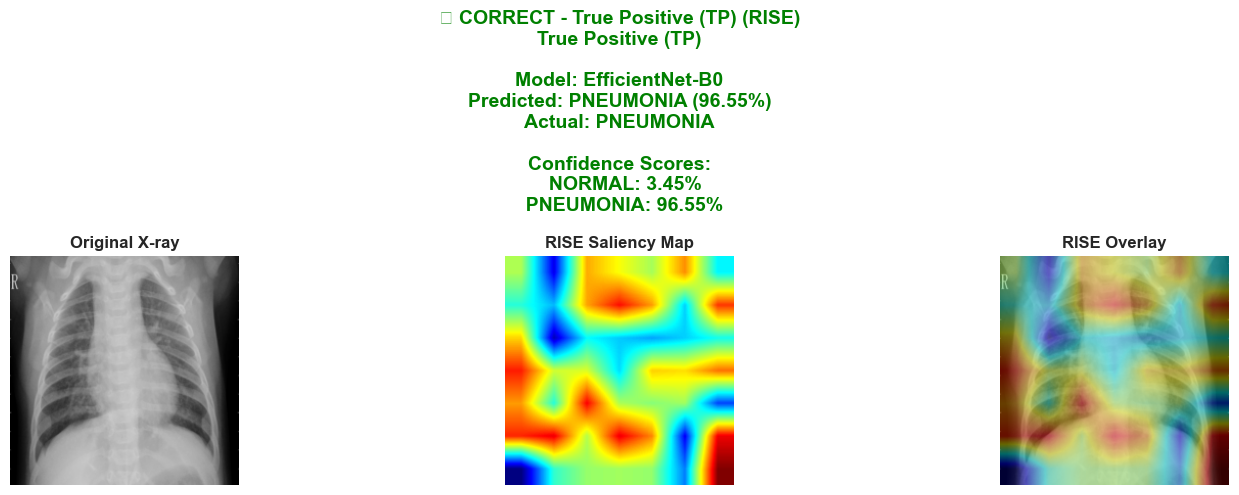


False Positive (FP): Model incorrectly predicted PNEUMONIA (actually NORMAL)
----------------------------------------------------------------------
  Generating RISE saliency map for False Positive (FP)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.37it/s]
/var/folders/2v/5f1pp9v54d7b2flcsjyy95x00000gn/T/ipykernel_9273/1229814044.py:90: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/haziqfaiz/Code/WQF7009-EXPLAINABLE-ARTIFICIAL-INTELLIGENCE-xAI-/xai-venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


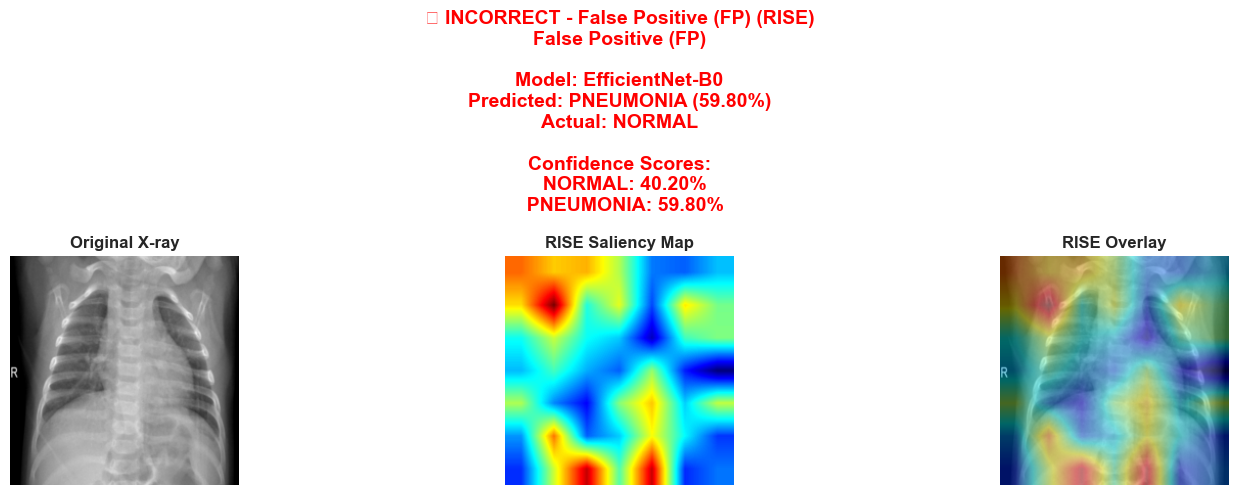


True Negative (TN): Model correctly identified NORMAL
----------------------------------------------------------------------
  Generating RISE saliency map for True Negative (TN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.34it/s]


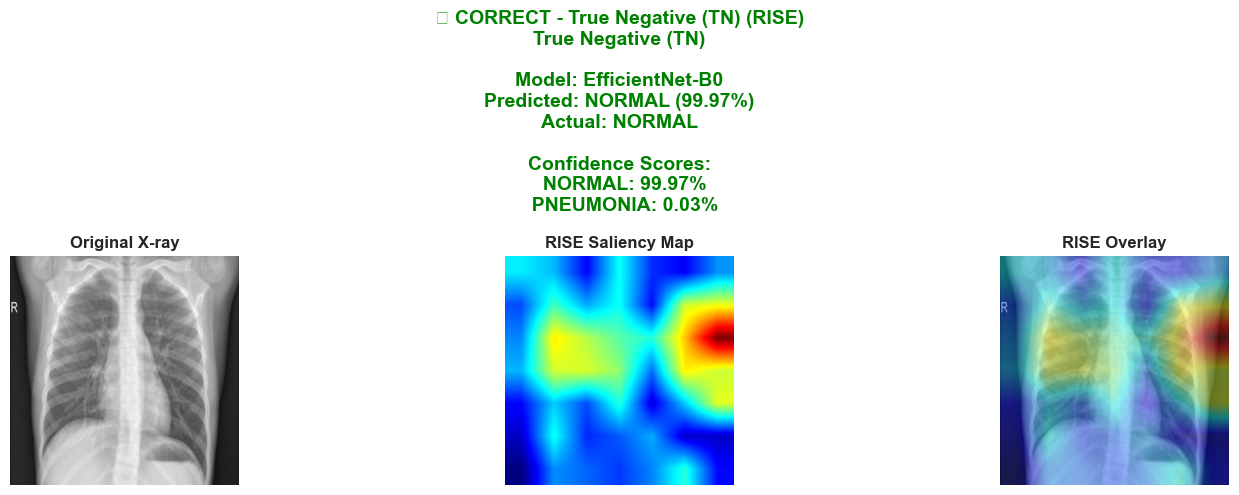


False Negative (FN): Model incorrectly predicted NORMAL (actually PNEUMONIA)
----------------------------------------------------------------------
  Generating RISE saliency map for False Negative (FN)...
Generating 1000 random masks...
Processing masks in batches of 50...


100%|██████████| 20/20 [00:02<00:00,  8.27it/s]


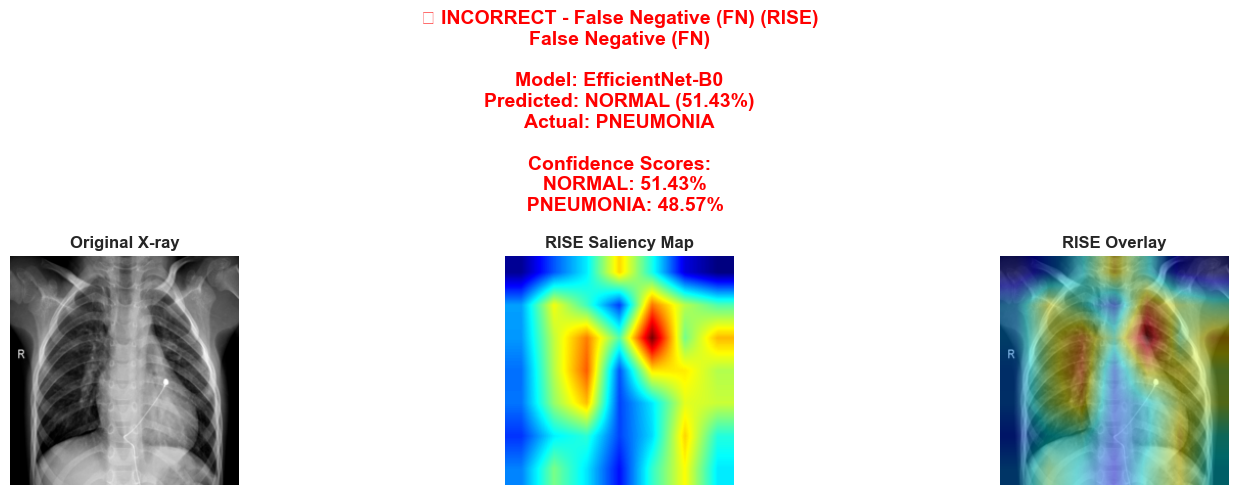


All RISE report visualizations complete!



In [110]:
categories_efficientnet_rise = create_rise_report_visualizations(model_efficient, "EfficientNet-B0", test_loader, class_names, device)